<a href="https://colab.research.google.com/github/herisantoso7007-ops/mall-customer-segmentation-7007/blob/main/Copy_of_Praktikum_Pertemuan1_Klasifikasiollama.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Praktikum Pertemuan 1 — Klasifikasi Prestasi Siswa
## Logistic Regression dan Decision Tree dengan UCI Student Performance Dataset

**Mata Kuliah:** Machine Learning / Advanced Machine Learning · **Program:** Magister Teknologi Informasi

Notebook ini adalah pendamping program untuk *Modul Pertemuan 1 — Klasifikasi*. Setiap bagian program dikaitkan dengan konsep matematika di modul, sehingga mahasiswa tidak hanya menjalankan `fit()` dan `predict()`, tetapi juga melihat **apa yang terjadi di dalam model**.

### Pertanyaan penelitian
> *Dapatkah karakteristik siswa, kebiasaan belajar, dukungan sosial, dan absensi digunakan untuk mengklasifikasikan apakah siswa akan lulus (G3 ≥ 10) atau tidak — **sebelum** nilai periode G1 dan G2 diketahui?*

### Struktur notebook
| No. | Bagian |
|---|---|
| 01 | Import library |
| 02 | Load dataset |
| 03 | Dataset overview |
| 04 | Exploratory Data Analysis |
| 05 | Definisi target (Pass/Fail) |
| 06 | Pemilihan feature (tanpa G1/G2) |
| 07 | Train-test split |
| 08 | Preprocessing pipeline |
| 09 | Logistic Regression: dari rumus ke kode |
| 10 | Model 1: Logistic Regression (scikit-learn) |
| 11 | Decision Tree: dari rumus ke kode |
| 12 | Model 2: Decision Tree (scikit-learn) |
| 13 | Evaluasi dan perbandingan model |
| 14 | Eksperimen data leakage (Model A vs B) |
| 15 | Mini early warning system |
| 16 | Tugas dan kesimpulan |

### Cara menggunakan
1. Jalankan sel dari atas ke bawah (**Runtime → Run all** di Google Colab).
2. Sel bertanda **✍️ TUGAS** harus dilengkapi mahasiswa.
3. Angka hasil dapat sedikit berbeda antar-lingkungan; **jangan menganggap angka sebagai hasil tetap**.

---
# 01. Import Library

In [ ]:
import os
import io
import zipfile
import urllib.request
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, log_loss, ConfusionMatrixDisplay
)

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid")

RANDOM_STATE = 42          # agar hasil dapat direproduksi
np.random.seed(RANDOM_STATE)
print("Library siap.")

Library siap.


---
# 02. Load Dataset

Dataset: **Student Performance — Mathematics** (`student-mat.csv`, 395 siswa) dari UCI Machine Learning Repository (ID 320).

Fungsi di bawah akan:
1. membaca `student-mat.csv` jika file sudah ada di folder kerja; atau
2. mengunduh arsip resmi UCI, mengekstrak `student-mat.csv`, lalu menyimpannya.

Jika unduhan gagal (misalnya jaringan kampus memblokir), unduh manual dari <https://archive.ics.uci.edu/dataset/320/student+performance>, lalu unggah `student-mat.csv` ke folder yang sama dengan notebook.

> **Catatan:** dataset UCI menggunakan separator `;`, bukan koma. Pustaka `ucimlrepo` (`fetch_ucirepo(id=320)`) tampaknya memuat versi 649 baris (Bahasa Portugis). Agar hasil satu kelas konsisten, praktikum ini memakai `student-mat.csv`.

In [ ]:
DATA_FILE = "student-mat.csv"
UCI_URL = "https://archive.ics.uci.edu/static/public/320/student+performance.zip"


def _find_in_zip(zbytes, target):
    # Cari file target di dalam zip, termasuk zip bersarang.
    with zipfile.ZipFile(io.BytesIO(zbytes)) as z:
        for name in z.namelist():
            if name.endswith(target):
                return z.read(name)
        for name in z.namelist():
            if name.endswith(".zip"):
                found = _find_in_zip(z.read(name), target)
                if found is not None:
                    return found
    return None


def load_student_data(path=DATA_FILE):
    if not os.path.exists(path):
        print("File tidak ditemukan, mengunduh dari UCI ...")
        raw = urllib.request.urlopen(UCI_URL, timeout=60).read()
        content = _find_in_zip(raw, os.path.basename(path))
        if content is None:
            raise FileNotFoundError(f"{path} tidak ditemukan di arsip UCI.")
        with open(path, "wb") as f:
            f.write(content)
        print("Tersimpan sebagai", path)
    return pd.read_csv(path, sep=";")


df = load_student_data()
print("Ukuran data:", df.shape)
df.head()

File tidak ditemukan, mengunduh dari UCI ...
Tersimpan sebagai student-mat.csv
Ukuran data: (395, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,reason,guardian,traveltime,studytime,failures,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,course,mother,2,2,0,yes,no,no,no,yes,yes,no,no,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,course,father,1,2,0,no,yes,no,no,no,yes,yes,no,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,other,mother,1,2,3,yes,no,yes,no,yes,yes,yes,no,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,home,mother,1,3,0,no,yes,yes,yes,yes,yes,yes,yes,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,home,father,1,2,0,no,yes,yes,no,yes,yes,no,no,4,3,2,1,2,5,4,6,10,10


---
# 03. Dataset Overview

Periksa jumlah baris/kolom, tipe data, dan missing values sebelum analisis.

In [ ]:
print("Jumlah baris :", df.shape[0])
print("Jumlah kolom :", df.shape[1])
print("\nMissing values total:", df.isna().sum().sum())
df.info()

Jumlah baris : 395
Jumlah kolom : 33

Missing values total: 0
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      395 non-null    object
 1   sex         395 non-null    object
 2   age         395 non-null    int64 
 3   address     395 non-null    object
 4   famsize     395 non-null    object
 5   Pstatus     395 non-null    object
 6   Medu        395 non-null    int64 
 7   Fedu        395 non-null    int64 
 8   Mjob        395 non-null    object
 9   Fjob        395 non-null    object
 10  reason      395 non-null    object
 11  guardian    395 non-null    object
 12  traveltime  395 non-null    int64 
 13  studytime   395 non-null    int64 
 14  failures    395 non-null    int64 
 15  schoolsup   395 non-null    object
 16  famsup      395 non-null    object
 17  paid        395 non-null    object
 18  activities  395 non-null    

In [ ]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
age,395.0,16.696203,1.276043,15.0,16.0,17.0,18.0,22.0
Medu,395.0,2.749367,1.094735,0.0,2.0,3.0,4.0,4.0
Fedu,395.0,2.521519,1.088201,0.0,2.0,2.0,3.0,4.0
traveltime,395.0,1.448101,0.697505,1.0,1.0,1.0,2.0,4.0
studytime,395.0,2.035443,0.839240,1.0,1.0,2.0,2.0,4.0
failures,395.0,0.334177,0.743651,0.0,0.0,0.0,0.0,3.0
famrel,395.0,3.944304,0.896659,1.0,4.0,4.0,5.0,5.0
freetime,395.0,3.235443,0.998862,1.0,3.0,3.0,4.0,5.0
goout,395.0,3.108861,1.113278,1.0,2.0,3.0,4.0,5.0
Dalc,395.0,1.481013,0.890741,1.0,1.0,1.0,2.0,5.0


Variabel yang dipakai dalam praktikum:

| Variabel | Keterangan | Variabel | Keterangan |
|---|---|---|---|
| school | Sekolah siswa (GP/MS) | studytime | Waktu belajar mingguan (1–4) |
| sex | Jenis kelamin | failures | Jumlah kegagalan kelas sebelumnya |
| age | Usia | schoolsup | Dukungan belajar dari sekolah |
| address | Urban/rural | famsup | Dukungan belajar dari keluarga |
| famsize | Ukuran keluarga | paid | Pelajaran tambahan berbayar |
| Pstatus | Status tinggal orang tua | activities | Aktivitas ekstrakurikuler |
| Medu / Fedu | Pendidikan ibu / ayah (0–4) | internet | Akses internet di rumah |
| absences | Jumlah ketidakhadiran | G1, G2, G3 | Nilai periode 1, 2, dan akhir (0–20) |

---
# 04. Exploratory Data Analysis

## 4.1 Distribusi nilai akhir G3

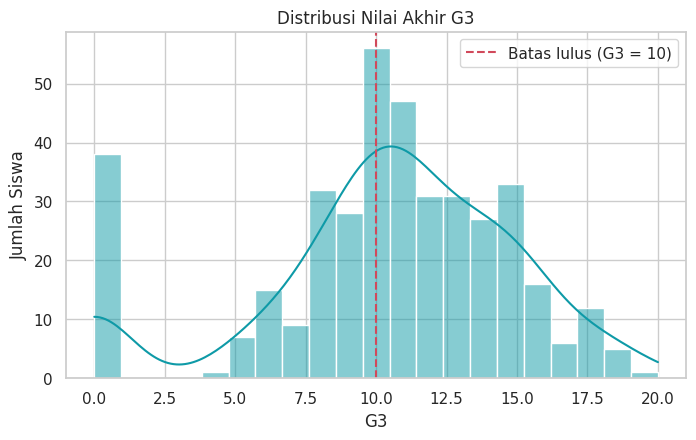

Siswa dengan G3 = 0: 38


In [ ]:
plt.figure(figsize=(8, 4.5))
sns.histplot(df["G3"], bins=21, kde=True, color="#0E9AA7")
plt.axvline(10, color="#D1495B", ls="--", label="Batas lulus (G3 = 10)")
plt.title("Distribusi Nilai Akhir G3")
plt.xlabel("G3")
plt.ylabel("Jumlah Siswa")
plt.legend()
plt.show()

print("Siswa dengan G3 = 0:", (df["G3"] == 0).sum())

**Pertanyaan diskusi:**
1. Apakah distribusi G3 normal?
2. Apakah terdapat siswa dengan nilai 0? Apa kemungkinan artinya?
3. Di mana nilai paling banyak terkonsentrasi?

## 4.2 Mengapa G1 dan G2 berbahaya untuk early prediction?

Lihat korelasi G1 dan G2 terhadap G3. Korelasi yang sangat tinggi menunjukkan bahwa keduanya hampir "membocorkan" jawaban.

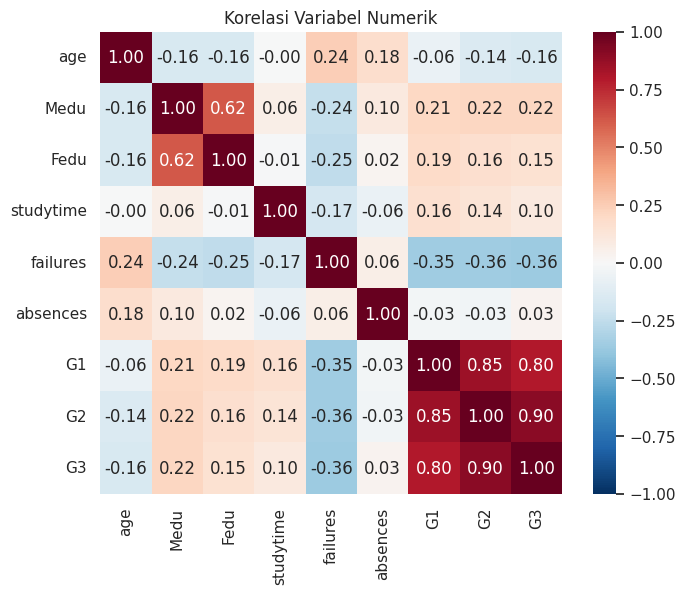

,G3
G2,0.905
G1,0.801
failures,-0.360
Medu,0.217
age,-0.162
Fedu,0.152
studytime,0.098
absences,0.034


In [ ]:
num_cols = ["age", "Medu", "Fedu", "studytime", "failures", "absences", "G1", "G2", "G3"]
corr = df[num_cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, square=True)
plt.title("Korelasi Variabel Numerik")
plt.show()

corr["G3"].drop("G3").sort_values(key=abs, ascending=False).round(3)

---
# 05. Definisi Target Klasifikasi

$$
Y = \begin{cases} 1 & \text{jika } G3 \geq 10 \quad (\text{Pass}) \\ 0 & \text{jika } G3 < 10 \quad (\text{Fail}) \end{cases}
$$

In [ ]:
df["pass"] = np.where(df["G3"] >= 10, 1, 0)
df[["G3", "pass"]].head(10)

,G3,pass
0,6,0
1,6,0
2,10,1
3,15,1
4,10,1
5,15,1
6,11,1
7,6,0
8,19,1
9,15,1


pass
Fail    130
Pass    265
Name: count, dtype: int64

Proporsi:
pass
Fail    0.329
Pass    0.671
Name: count, dtype: float64


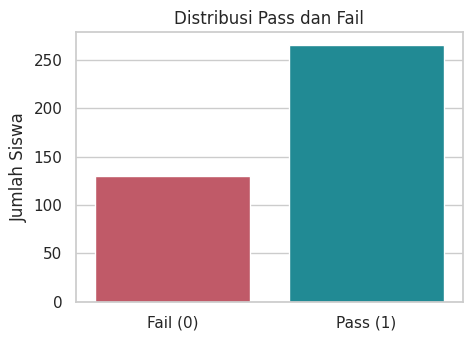

In [ ]:
counts = df["pass"].value_counts().sort_index()
print(counts.rename({0: "Fail", 1: "Pass"}))
print("\nProporsi:")
print((counts / counts.sum()).round(3).rename({0: "Fail", 1: "Pass"}))

plt.figure(figsize=(5, 3.5))
sns.countplot(data=df, x="pass", hue="pass", palette=["#D1495B", "#0E9AA7"], legend=False)
plt.xticks([0, 1], ["Fail (0)", "Pass (1)"])
plt.title("Distribusi Pass dan Fail")
plt.xlabel("")
plt.ylabel("Jumlah Siswa")
plt.show()

> **Accuracy saja tidak selalu cukup.** Jika mayoritas siswa lulus, model yang selalu menjawab "Pass" sudah mendapat accuracy tinggi — tetapi tidak menemukan satu pun siswa yang gagal. Baseline di bawah menunjukkan hal ini.

In [ ]:
baseline_acc = counts.max() / counts.sum()
print(f"Accuracy model 'selalu Pass' (baseline mayoritas): {baseline_acc:.3f}")
print("Recall kelas Fail untuk baseline ini: 0.000")

Accuracy model 'selalu Pass' (baseline mayoritas): 0.671
Recall kelas Fail untuk baseline ini: 0.000


## 4.3 EDA terhadap target

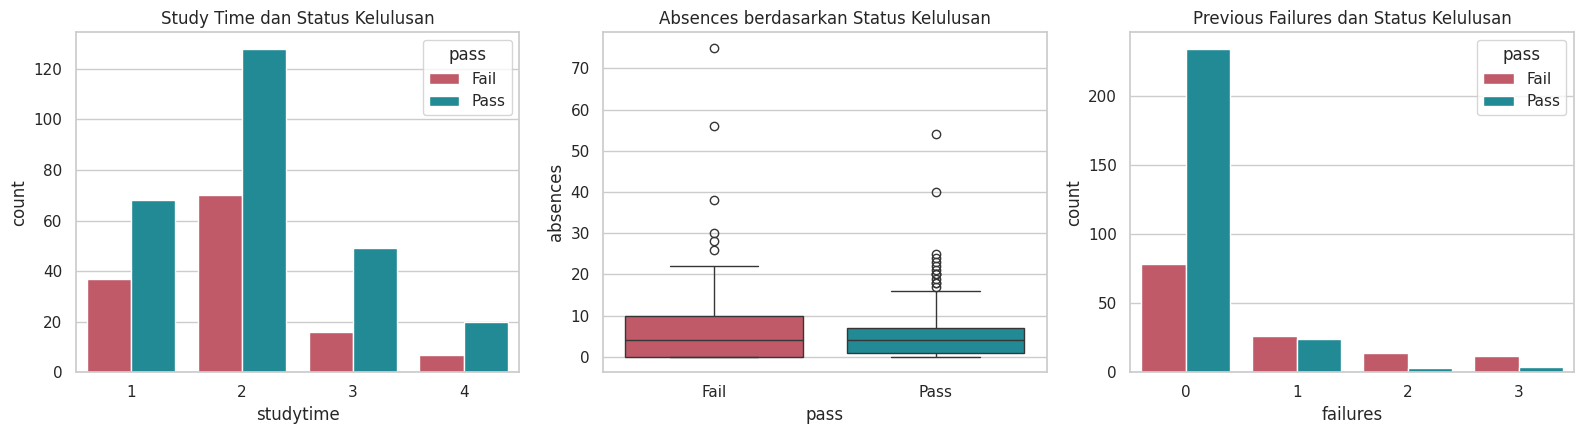

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
palette = {0: "#D1495B", 1: "#0E9AA7"}

sns.countplot(data=df, x="studytime", hue="pass", palette=palette, ax=axes[0])
axes[0].set_title("Study Time dan Status Kelulusan")

sns.boxplot(data=df, x="pass", y="absences", hue="pass", palette=palette, legend=False, ax=axes[1])
axes[1].set_xticks([0, 1], ["Fail", "Pass"])
axes[1].set_title("Absences berdasarkan Status Kelulusan")

sns.countplot(data=df, x="failures", hue="pass", palette=palette, ax=axes[2])
axes[2].set_title("Previous Failures dan Status Kelulusan")

for ax in (axes[0], axes[2]):
    ax.legend(title="pass", labels=["Fail", "Pass"])
plt.tight_layout()
plt.show()

In [ ]:
# Proporsi lulus per kategori — lebih mudah dibandingkan daripada jumlah mentah
for col in ["studytime", "failures"]:
    print(f"\nProporsi Pass per {col}:")
    print(df.groupby(col)["pass"].agg(["mean", "count"]).round(3))


Proporsi Pass per studytime:
            mean  count
studytime              
1          0.648    105
2          0.646    198
3          0.754     65
4          0.741     27

Proporsi Pass per failures:
           mean  count
failures              
0         0.750    312
1         0.480     50
2         0.176     17
3         0.250     16


> **Pola ≠ sebab-akibat.** Hubungan statistik antara `failures` atau `absences` dengan kelulusan **tidak otomatis** berarti faktor tersebut menyebabkan kelulusan/kegagalan. Hal ini dibahas lebih lanjut di Pertemuan 4 (Causal Inference).

---
# 06. Pemilihan Feature (Early Prediction)

G1, G2, dan G3 **sengaja tidak digunakan** sebagai feature. Model hanya memakai informasi yang tersedia di awal semester.

In [ ]:
numeric_features = ["age", "Medu", "Fedu", "studytime", "failures", "absences"]
categorical_features = ["school", "sex", "address", "famsize", "Pstatus",
                        "schoolsup", "famsup", "paid", "activities", "internet"]
features = numeric_features + categorical_features

X = df[features]
y = df["pass"]
print("Jumlah feature:", len(features))
X.head()

Jumlah feature: 16


,age,Medu,Fedu,studytime,failures,absences,school,sex,address,famsize,Pstatus,schoolsup,famsup,paid,activities,internet
0,18,4,4,2,0,6,GP,F,U,GT3,A,yes,no,no,no,no
1,17,1,1,2,0,4,GP,F,U,GT3,T,no,yes,no,no,yes
2,15,1,1,2,3,10,GP,F,U,LE3,T,yes,no,yes,no,yes
3,15,4,2,3,0,2,GP,F,U,GT3,T,no,yes,yes,yes,yes
4,16,3,3,2,0,4,GP,F,U,GT3,T,no,yes,yes,no,no


---
# 07. Train-Test Split

Data dibagi 80% training dan 20% testing. `stratify=y` menjaga proporsi Pass/Fail tetap sama pada kedua bagian.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

print("Training:", X_train.shape, "| Testing:", X_test.shape)
print("Proporsi Pass — train: %.3f | test: %.3f" % (y_train.mean(), y_test.mean()))

Training: (316, 16) | Testing: (79, 16)
Proporsi Pass — train: 0.671 | test: 0.671


---
# 08. Preprocessing Pipeline

* **Numerik** → `StandardScaler` (rata-rata 0, simpangan baku 1)
* **Kategorikal** → `OneHotEncoder` (misalnya `internet` → `internet_no`, `internet_yes`)

Preprocessing dimasukkan ke dalam `Pipeline` agar scaler dan encoder **hanya di-fit pada data training**, sehingga mengurangi risiko data leakage dan menjaga konsistensi training–testing.

In [ ]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features),
    ]
)

# Lihat hasil transformasi (hanya untuk ilustrasi)
demo = clone(preprocessor).fit(X_train)
X_demo = pd.DataFrame(demo.transform(X_train[:5]), columns=demo.get_feature_names_out())
X_demo.round(2)

,num__age,num__Medu,num__Fedu,num__studytime,num__failures,num__absences,cat__school_GP,cat__school_MS,cat__sex_F,cat__sex_M,cat__address_R,cat__address_U,cat__famsize_GT3,cat__famsize_LE3,cat__Pstatus_A,cat__Pstatus_T,cat__schoolsup_no,cat__schoolsup_yes,cat__famsup_no,cat__famsup_yes,cat__paid_no,cat__paid_yes,cat__activities_no,cat__activities_yes,cat__internet_no,cat__internet_yes
0,-1.31,1.14,0.46,2.39,-0.44,-0.69,1.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0,1.0
1,-0.52,-0.67,-1.39,-1.26,-0.44,0.06,1.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0
2,-1.31,-1.57,-1.39,-1.26,-0.44,-0.69,1.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,1.0
3,1.82,0.23,-0.46,-1.26,3.55,-0.69,1.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0,1.0
4,1.04,1.14,1.39,-1.26,-0.44,0.18,0.0,1.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0


---
# 09. Logistic Regression: Dari Rumus ke Kode

Bagian ini menerjemahkan rumus di **Bagian II modul** menjadi program. Tujuannya membuktikan bahwa `LogisticRegression` di scikit-learn bukan "kotak hitam".

## 9.1 Fungsi sigmoid

$$\sigma(z) = \frac{1}{1 + e^{-z}}$$

z = -5  ->  sigma(z) = 0.007
z = -2  ->  sigma(z) = 0.119
z = -1  ->  sigma(z) = 0.269
z =  0  ->  sigma(z) = 0.500
z =  1  ->  sigma(z) = 0.731
z =  2  ->  sigma(z) = 0.881
z =  5  ->  sigma(z) = 0.993


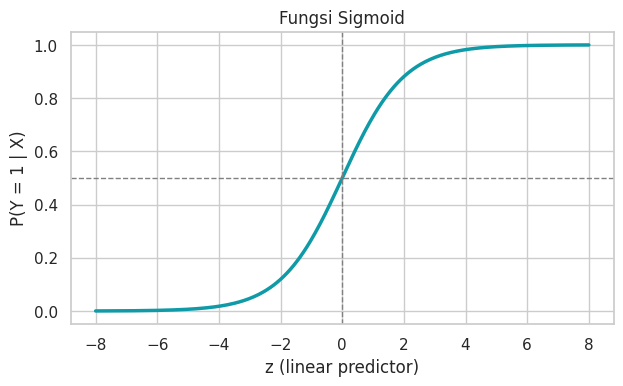

In [ ]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

for z in [-5, -2, -1, 0, 1, 2, 5]:
    print(f"z = {z:>2}  ->  sigma(z) = {sigmoid(z):.3f}")

z = np.linspace(-8, 8, 300)
plt.figure(figsize=(7, 3.8))
plt.plot(z, sigmoid(z), color="#0E9AA7", lw=2.5)
plt.axhline(0.5, color="gray", ls="--", lw=1)
plt.axvline(0, color="gray", ls="--", lw=1)
plt.title("Fungsi Sigmoid")
plt.xlabel("z (linear predictor)")
plt.ylabel("P(Y = 1 | X)")
plt.show()

## 9.2 Contoh perhitungan manual

Model ilustrasi dengan dua feature: $z = -2 + 0{,}8\,\text{studytime} - 1{,}2\,\text{failures}$

In [ ]:
b0, b_study, b_fail = -2.0, 0.8, -1.2

def manual_predict(studytime, failures, threshold=0.5):
    z = b0 + b_study * studytime + b_fail * failures
    p = sigmoid(z)
    kelas = "Pass" if p >= threshold else "Fail"
    return z, p, kelas

for nama, st, fl in [("Siswa A", 3, 1), ("Siswa B", 4, 0)]:
    z, p, k = manual_predict(st, fl)
    print(f"{nama}: studytime={st}, failures={fl} -> z = {z:.2f}, P(Pass) = {p:.3f} -> {k}")

Siswa A: studytime=3, failures=1 -> z = -0.80, P(Pass) = 0.310 -> Fail
Siswa B: studytime=4, failures=0 -> z = 1.20, P(Pass) = 0.769 -> Pass


## 9.3 Odds, logit, dan odds ratio

$$\text{Odds} = \frac{p}{1-p}, \qquad \log\frac{p}{1-p} = \beta_0 + \beta_1 x_1 + \cdots, \qquad OR = e^{\beta}$$

In [ ]:
p = 0.8
print(f"p = {p} -> odds = {p/(1-p):.2f} -> logit = {np.log(p/(1-p)):.3f}")

for beta in [0.5, -0.8, -0.15]:
    print(f"beta = {beta:>5} -> odds ratio = e^beta = {np.exp(beta):.3f}")

# Bukti: sigmoid adalah invers dari logit
p_vals = np.array([0.1, 0.5, 0.9])
logit = np.log(p_vals / (1 - p_vals))
print("\nsigmoid(logit(p)) =", sigmoid(logit).round(6), "== p")

p = 0.8 -> odds = 4.00 -> logit = 1.386
beta =   0.5 -> odds ratio = e^beta = 1.649
beta =  -0.8 -> odds ratio = e^beta = 0.449
beta = -0.15 -> odds ratio = e^beta = 0.861

sigmoid(logit(p)) = [0.1 0.5 0.9] == p


## 9.4 Binary cross-entropy (log loss)

$$J(\beta) = -\frac{1}{n}\sum_{i=1}^{n}\left[y_i \log p_i + (1-y_i)\log(1-p_i)\right]$$

Cross-entropy menghukum keras prediksi yang **yakin tetapi salah**.

In [ ]:
def binary_cross_entropy(y_true, p, eps=1e-12):
    p = np.clip(p, eps, 1 - eps)
    return -np.mean(y_true * np.log(p) + (1 - y_true) * np.log(1 - p))

for p in [0.99, 0.70, 0.30, 0.01]:
    print(f"y = 1, p = {p:.2f} -> loss = {binary_cross_entropy(np.array([1]), np.array([p])):.3f}")

y = 1, p = 0.99 -> loss = 0.010
y = 1, p = 0.70 -> loss = 0.357
y = 1, p = 0.30 -> loss = 1.204
y = 1, p = 0.01 -> loss = 4.605


## 9.5 Gradient descent dari nol

Update parameter:

$$\beta \leftarrow \beta - \alpha \,\frac{1}{n} X^{T}(p - y)$$

Kita latih Logistic Regression **tanpa scikit-learn** menggunakan data training yang sudah dipreprocessing, lalu bandingkan hasilnya dengan scikit-learn.

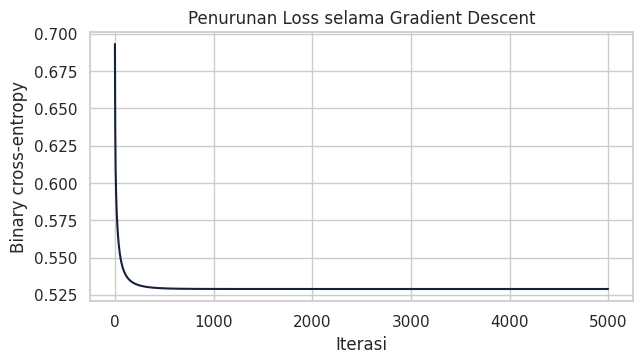

Loss awal : 0.6931
Loss akhir: 0.5289


In [ ]:
prep_gd = clone(preprocessor).fit(X_train)
Xtr = prep_gd.transform(X_train)
Xte = prep_gd.transform(X_test)
Xtr = Xtr.toarray() if hasattr(Xtr, "toarray") else Xtr
Xte = Xte.toarray() if hasattr(Xte, "toarray") else Xte

# Tambahkan kolom 1 untuk intercept beta_0
Xtr_b = np.column_stack([np.ones(len(Xtr)), Xtr])
Xte_b = np.column_stack([np.ones(len(Xte)), Xte])
ytr = y_train.to_numpy()


def train_logreg_gd(X, y, lr=0.1, n_iter=5000):
    beta = np.zeros(X.shape[1])
    history = []
    for _ in range(n_iter):
        p = sigmoid(X @ beta)                 # 1) prediksi
        grad = X.T @ (p - y) / len(y)         # 2) gradient
        beta -= lr * grad                     # 3) update
        history.append(binary_cross_entropy(y, p))
    return beta, history


beta_gd, loss_history = train_logreg_gd(Xtr_b, ytr)

plt.figure(figsize=(7, 3.5))
plt.plot(loss_history, color="#16213E")
plt.title("Penurunan Loss selama Gradient Descent")
plt.xlabel("Iterasi")
plt.ylabel("Binary cross-entropy")
plt.show()

print(f"Loss awal : {loss_history[0]:.4f}")
print(f"Loss akhir: {loss_history[-1]:.4f}")

In [ ]:
# Bandingkan dengan scikit-learn (C sangat besar = regularisasi sangat lemah, agar setara)
sk_lr = LogisticRegression(C=1e6, max_iter=10000).fit(Xtr, ytr)
beta_sk = np.concatenate([sk_lr.intercept_, sk_lr.coef_[0]])

names = ["intercept"] + list(prep_gd.get_feature_names_out())
compare = pd.DataFrame({"feature": names, "beta_gradient_descent": beta_gd, "beta_sklearn": beta_sk})
print("Korelasi koefisien GD vs sklearn:", np.corrcoef(beta_gd, beta_sk)[0, 1].round(4))

acc_gd = accuracy_score(y_test, (sigmoid(Xte_b @ beta_gd) >= 0.5).astype(int))
acc_sk = accuracy_score(y_test, sk_lr.predict(Xte))
print(f"Accuracy test — GD manual: {acc_gd:.3f} | sklearn: {acc_sk:.3f}")
compare.round(3).head(10)

Korelasi koefisien GD vs sklearn: 1.0
Accuracy test — GD manual: 0.658 | sklearn: 0.658


,feature,beta_gradient_descent,beta_sklearn
0,intercept,0.157,0.157
1,num__age,-0.264,-0.264
2,num__Medu,0.066,0.066
3,num__Fedu,0.036,0.037
4,num__studytime,0.122,0.122
5,num__failures,-0.885,-0.885
6,num__absences,-0.138,-0.138
7,cat__school_GP,-0.032,-0.032
8,cat__school_MS,0.190,0.189
9,cat__sex_F,-0.117,-0.117


> **Interpretasi:** koefisien hasil gradient descent manual dan scikit-learn searah dan sangat mirip. Perbedaan kecil wajar karena jumlah iterasi, learning rate, dan algoritma optimisasi yang berbeda. Dengan kata lain, `fit()` pada dasarnya **meminimalkan cross-entropy**.

---
# 10. Model 1: Logistic Regression (scikit-learn)

Sekarang gunakan pipeline lengkap. `clone(preprocessor)` memastikan setiap model memiliki salinan preprocessor sendiri.

In [ ]:
logistic_model = Pipeline(steps=[
    ("preprocessor", clone(preprocessor)),
    ("classifier", LogisticRegression(max_iter=1000)),
])
logistic_model.fit(X_train, y_train)

y_pred_lr = logistic_model.predict(X_test)
y_prob_lr = logistic_model.predict_proba(X_test)   # kolom 0 = P(Fail), kolom 1 = P(Pass)

pd.DataFrame(y_prob_lr[:5], columns=["P(Fail)", "P(Pass)"]).round(3)

,P(Fail),P(Pass)
0,0.687,0.313
1,0.721,0.279
2,0.304,0.696
3,0.320,0.680
4,0.242,0.758


## 10.1 Probabilitas → kelas secara manual

$\hat{Y} = I(p \geq 0{,}5)$ — hasilnya harus identik dengan `predict()`.

In [ ]:
prob_pass = y_prob_lr[:, 1]
y_pred_manual = (prob_pass >= 0.5).astype(int)
print("Sama dengan predict():", np.array_equal(y_pred_manual, y_pred_lr))

Sama dengan predict(): True


## 10.2 Koefisien dan odds ratio

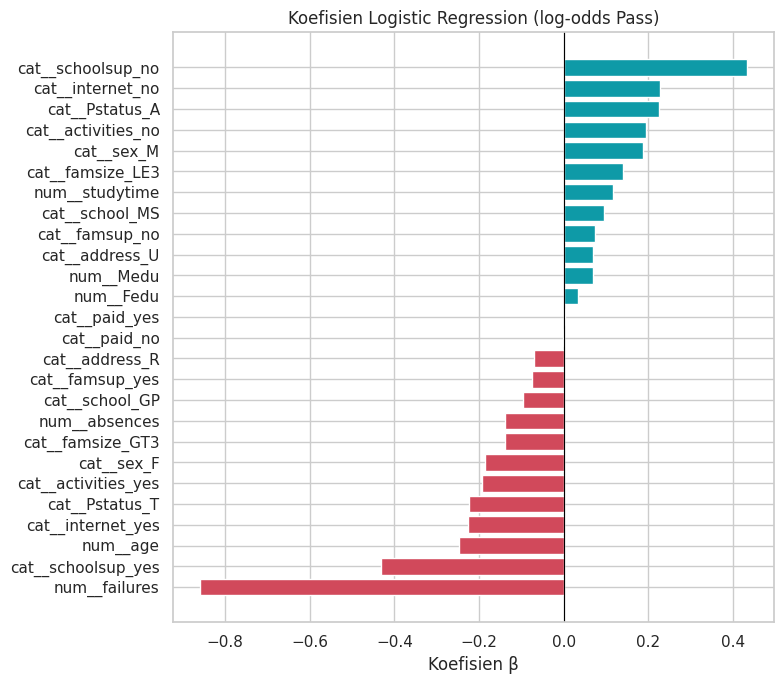

,feature,coefficient,odds_ratio
16,cat__schoolsup_no,0.432,1.541
24,cat__internet_no,0.227,1.255
14,cat__Pstatus_A,0.225,1.252
22,cat__activities_no,0.194,1.214
9,cat__sex_M,0.187,1.206
13,cat__famsize_LE3,0.140,1.150
3,num__studytime,0.117,1.124
7,cat__school_MS,0.096,1.101
18,cat__famsup_no,0.075,1.078
11,cat__address_U,0.069,1.072


In [ ]:
clf = logistic_model.named_steps["classifier"]
feature_names = logistic_model.named_steps["preprocessor"].get_feature_names_out()

coef_df = pd.DataFrame({"feature": feature_names, "coefficient": clf.coef_[0]})
coef_df["odds_ratio"] = np.exp(coef_df["coefficient"])
coef_df = coef_df.sort_values("coefficient")

plt.figure(figsize=(8, 7))
colors = ["#D1495B" if c < 0 else "#0E9AA7" for c in coef_df["coefficient"]]
plt.barh(coef_df["feature"], coef_df["coefficient"], color=colors)
plt.axvline(0, color="black", lw=0.8)
plt.title("Koefisien Logistic Regression (log-odds Pass)")
plt.xlabel("Koefisien β")
plt.tight_layout()
plt.show()

coef_df.sort_values("odds_ratio", ascending=False).round(3)

> **Hati-hati menafsirkan.** Karena feature numerik di-standardisasi, "kenaikan satu unit" berarti **kenaikan satu simpangan baku**. Interpretasi yang tepat, misalnya untuk `absences`:
>
> *"Dalam model Logistic Regression, dengan feature lain tetap, kenaikan satu simpangan baku absensi berasosiasi dengan perubahan log-odds kelulusan sebesar β; odds kelulusan yang diprediksi model dikalikan $e^{\beta}$."*
>
> Ini **bukan** bukti bahwa absensi menyebabkan kegagalan.

## 10.3 Pengaruh threshold terhadap early warning

Threshold 0,5 bukan hukum matematis. Di sini kita menandai siswa sebagai **berisiko (Fail)** jika `P(Fail) ≥ t`, lalu melihat trade-off antara recall kelas Fail dan jumlah siswa yang ditandai.

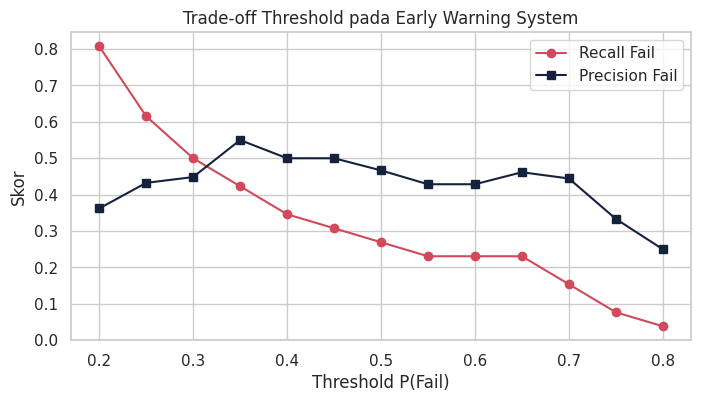

,threshold P(Fail),ditandai berisiko,recall Fail,precision Fail
0,0.20,58,0.808,0.362
1,0.25,37,0.615,0.432
2,0.30,29,0.500,0.448
3,0.35,20,0.423,0.550
4,0.40,18,0.346,0.500
5,0.45,16,0.308,0.500
6,0.50,15,0.269,0.467
7,0.55,14,0.231,0.429
8,0.60,14,0.231,0.429
9,0.65,13,0.231,0.462


In [ ]:
prob_fail = y_prob_lr[:, 0]
rows = []
for t in np.arange(0.20, 0.81, 0.05):
    flag = (prob_fail >= t).astype(int)          # 1 = ditandai berisiko
    actual_fail = (y_test.to_numpy() == 0).astype(int)
    rows.append({
        "threshold P(Fail)": round(t, 2),
        "ditandai berisiko": flag.sum(),
        "recall Fail": recall_score(actual_fail, flag, zero_division=0),
        "precision Fail": precision_score(actual_fail, flag, zero_division=0),
    })
thr_df = pd.DataFrame(rows)

plt.figure(figsize=(8, 4))
plt.plot(thr_df["threshold P(Fail)"], thr_df["recall Fail"], "o-", color="#D1495B", label="Recall Fail")
plt.plot(thr_df["threshold P(Fail)"], thr_df["precision Fail"], "s-", color="#16213E", label="Precision Fail")
plt.xlabel("Threshold P(Fail)")
plt.ylabel("Skor")
plt.title("Trade-off Threshold pada Early Warning System")
plt.legend()
plt.show()

thr_df.round(3)

**Diskusi:** threshold mana yang Anda pilih jika sekolah lebih mengutamakan tidak ada siswa berisiko yang terlewat? Apa konsekuensinya bagi beban konselor?

In [ ]:
# ======================================================================
# PROGRAM KLASIFIKASI SUPPORT VECTOR MACHINE (SVM) & TAHAPANNYA
# ======================================================================

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.svm import SVC
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, ConfusionMatrixDisplay

print("=== TAHAP 1: INISIALISASI MODEL SVM ===")
# Support Vector Machine (SVM) bekerja dengan mencari hyperplane terbaik yang memaksimalkan
# margin antar kelas. Kita menggunakan kernel RBF (Radial Basis Function) agar mampu menangani
# pola non-linear, serta mengatur parameter regulasi C=1.0 dan probability=True agar model
# dapat menghasilkan probabilitas prediksi.
svm_classifier = SVC(
    kernel="rbf",
    C=1.0,
    gamma="scale",
    probability=True,
    random_state=RANDOM_STATE
)
print("✔ Model SVM dengan kernel RBF berhasil diinisialisasi.\n")


print("=== TAHAP 2: PROSES TRANSFORMATION DATA (PREPROCESSING) ===")
# SVM sangat sensitif terhadap skala data karena mengukur jarak geometris antar titik sampel.
# Oleh karena itu, kita mentransformasikan fitur X menggunakan pipeline 'preprocessor'
# yang melakukan Standardisasi (StandardScaler) dan One-Hot Encoding.
X_train_preprocessed = preprocessor.transform(X_train)
X_test_preprocessed = preprocessor.transform(X_test)
print(f"✔ Data training berhasil diproses. Dimensi baru: {X_train_preprocessed.shape}")
print(f"✔ Data testing berhasil diproses. Dimensi baru: {X_test_preprocessed.shape}\n")


print("=== TAHAP 3: PROSES TRAINING (FITTING) MODEL ===")
# Proses 'fit' akan mencari support vectors (titik-titik data terdekat dengan batas keputusan)
# untuk membentuk margin pemisah optimal di ruang dimensi tinggi.
svm_classifier.fit(X_train_preprocessed, y_train)
print("✔ Model SVM berhasil dilatih menggunakan data training.\n")


print("=== TAHAP 4: PREDIKSI DATA UJI (TESTING) ===")
# Memprediksi kelas kelulusan (Pass/Fail) dan mendapatkan probabilitas prediksi untuk data uji.
y_pred_svm = svm_classifier.predict(X_test_preprocessed)
y_prob_svm = svm_classifier.predict_proba(X_test_preprocessed)
print("✔ Prediksi selesai dilakukan pada data uji.\n")


print("=== TAHAP 5: EVALUASI KINERJA MODEL ===")
# Mengukur akurasi keseluruhan dan melihat laporan klasifikasi terperinci (Precision, Recall, F1-Score).
acc_svm = accuracy_score(y_test, y_pred_svm)
print(f"Akurasi Model SVM: {acc_svm:.3f} ({acc_svm*100:.1f}%)")
print("\nLaporan Klasifikasi Lengkap:")
print(classification_report(y_test, y_pred_svm, target_names=["Fail", "Pass"], zero_division=0))

# Menampilkan Confusion Matrix secara visual untuk menganalisis performa deteksi kelas Pass & Fail
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_svm, display_labels=["Fail", "Pass"], cmap="Blues", ax=ax
)
plt.title("Confusion Matrix - Support Vector Machine (SVM)")
plt.grid(False)
plt.show()

=== TAHAP 1: INISIALISASI MODEL SVM ===
✔ Model SVM dengan kernel RBF berhasil diinisialisasi.

=== TAHAP 2: PROSES TRANSFORMATION DATA (PREPROCESSING) ===


NotFittedError: This ColumnTransformer instance is not fitted yet. Call 'fit' with appropriate arguments before using this estimator.

---
# 11. Decision Tree: Dari Rumus ke Kode

## 11.1 Entropy dan Gini

$$H(D) = -\sum_k p_k \log_2 p_k \qquad\qquad G(D) = 1 - \sum_k p_k^2$$

In [ ]:
def entropy(labels):
    _, counts = np.unique(labels, return_counts=True)
    p = counts / counts.sum()
    return -np.sum(p * np.log2(p))


def gini(labels):
    _, counts = np.unique(labels, return_counts=True)
    p = counts / counts.sum()
    return 1 - np.sum(p ** 2)


print("7 Pass, 3 Fail  -> entropy = %.3f" % entropy([1] * 7 + [0] * 3))
print("5 Pass, 5 Fail  -> entropy = %.3f | gini = %.3f" % (entropy([1] * 5 + [0] * 5), gini([1] * 5 + [0] * 5)))
print("10 Pass, 0 Fail -> entropy = %.3f | gini = %.3f" % (entropy([1] * 10), gini([1] * 10)))

p = np.linspace(0.001, 0.999, 200)
plt.figure(figsize=(7, 3.8))
plt.plot(p, -(p * np.log2(p) + (1 - p) * np.log2(1 - p)), label="Entropy", color="#16213E", lw=2)
plt.plot(p, 1 - p**2 - (1 - p)**2, label="Gini", color="#F29E4C", lw=2)
plt.xlabel("Proporsi kelas Pass")
plt.ylabel("Impurity")
plt.title("Entropy vs Gini (klasifikasi biner)")
plt.legend()
plt.show()

## 11.2 Information gain — contoh 100 siswa

60 Pass / 40 Fail, di-split menjadi kiri (10 P / 30 F) dan kanan (50 P / 10 F).

In [ ]:
parent = [1] * 60 + [0] * 40
left = [1] * 10 + [0] * 30
right = [1] * 50 + [0] * 10

h_parent = entropy(parent)
h_after = len(left) / 100 * entropy(left) + len(right) / 100 * entropy(right)
print(f"H(parent) = {h_parent:.3f}")
print(f"H(left)   = {entropy(left):.3f} | H(right) = {entropy(right):.3f}")
print(f"H sesudah = {h_after:.3f}")
print(f"Information Gain = {h_parent - h_after:.3f}")

## 11.3 Mencari split terbaik dari nol — contoh 10 siswa

Algoritma greedy: coba setiap feature dan setiap kandidat threshold (titik tengah nilai berurutan), hitung penurunan impurity

$$\Delta I = I(t) - \frac{N_L}{N_t} I(t_L) - \frac{N_R}{N_t} I(t_R)$$

lalu pilih yang terbesar.

In [ ]:
toy = pd.DataFrame({
    "failures":  [0, 0, 0, 0, 1, 1, 1, 2, 2, 3],
    "studytime": [4, 3, 3, 2, 3, 2, 2, 2, 1, 1],
    "target":    ["Pass"] * 5 + ["Fail"] * 5,
})
toy_y = (toy["target"] == "Pass").astype(int).to_numpy()


def candidate_thresholds(values):
    v = np.unique(values)
    return (v[:-1] + v[1:]) / 2          # titik tengah


def impurity_reduction(x, y, t, criterion=gini):
    left, right = y[x <= t], y[x > t]
    weighted = len(left) / len(y) * criterion(left) + len(right) / len(y) * criterion(right)
    return criterion(y) - weighted


rows = []
for col in ["failures", "studytime"]:
    for t in candidate_thresholds(toy[col]):
        rows.append({"feature": col, "threshold": f"<= {t}",
                     "delta_gini": impurity_reduction(toy[col].to_numpy(), toy_y, t)})

splits = pd.DataFrame(rows).sort_values("delta_gini", ascending=False)
print("Gini awal:", gini(toy_y))
splits.round(3)

> Perhatikan: `failures <= 0.5` dan `studytime <= 2.5` menghasilkan ΔGini yang **sama** (0,333). Implementasi nyata memecah hasil seri dengan aturan tertentu (misalnya urutan feature atau pemilihan acak). Ini menjadi bahan diskusi **Tugas 3**.

In [ ]:
# Bandingkan dengan scikit-learn: pohon satu tingkat (decision stump)
stump = DecisionTreeClassifier(max_depth=1, criterion="gini", random_state=RANDOM_STATE)
stump.fit(toy[["failures", "studytime"]], toy_y)
print(export_text(stump, feature_names=["failures", "studytime"]))

---
# 12. Model 2: Decision Tree (scikit-learn)

In [ ]:
tree_model = Pipeline(steps=[
    ("preprocessor", clone(preprocessor)),
    ("classifier", DecisionTreeClassifier(criterion="gini", max_depth=4, random_state=RANDOM_STATE)),
])
tree_model.fit(X_train, y_train)

y_pred_tree = tree_model.predict(X_test)
print(classification_report(y_test, y_pred_tree, target_names=["Fail", "Pass"], zero_division=0))

## 12.1 Pohon yang mudah dibaca (feature asli, tanpa scaling)

Di dalam pipeline, threshold numerik tampil dalam skala terstandardisasi. Karena Decision Tree **tidak memerlukan scaling**, kita latih pohon terpisah pada tiga feature asli agar aturan IF-THEN mudah dibaca.

In [ ]:
simple_features = ["studytime", "failures", "absences"]
Xs_train, Xs_test = X_train[simple_features], X_test[simple_features]

simple_tree = DecisionTreeClassifier(criterion="gini", max_depth=3, random_state=RANDOM_STATE)
simple_tree.fit(Xs_train, y_train)
print("Accuracy test (3 feature):", round(accuracy_score(y_test, simple_tree.predict(Xs_test)), 3))

plt.figure(figsize=(18, 8))
plot_tree(simple_tree, feature_names=simple_features, class_names=["Fail", "Pass"],
          filled=True, rounded=True, fontsize=10)
plt.title("Decision Tree (max_depth = 3)")
plt.show()

In [ ]:
# Aturan IF-THEN dalam bentuk teks
print(export_text(simple_tree, feature_names=simple_features))

**Cara membaca node:** `gini` = impurity node; `samples` = jumlah observasi; `value` = [jumlah Fail, jumlah Pass]; `class` = kelas mayoritas (prediksi node).

## 12.2 Overfitting: pengaruh kedalaman pohon

In [ ]:
depths = range(1, 16)
train_acc, test_acc = [], []
for d in depths:
    m = Pipeline([("preprocessor", clone(preprocessor)),
                  ("classifier", DecisionTreeClassifier(max_depth=d, random_state=RANDOM_STATE))])
    m.fit(X_train, y_train)
    train_acc.append(accuracy_score(y_train, m.predict(X_train)))
    test_acc.append(accuracy_score(y_test, m.predict(X_test)))

plt.figure(figsize=(8, 4))
plt.plot(depths, train_acc, "o-", color="#16213E", label="Training")
plt.plot(depths, test_acc, "s-", color="#D1495B", label="Testing")
plt.xlabel("max_depth")
plt.ylabel("Accuracy")
plt.title("Bias–Variance: Accuracy vs Kedalaman Pohon")
plt.legend()
plt.show()

> Semakin dalam pohon, accuracy training mendekati 1, tetapi accuracy testing tidak ikut naik — ini tanda **overfitting** (variance tinggi). Parameter `max_depth`, `min_samples_leaf`, dan `ccp_alpha` dipakai untuk mengendalikannya.

## 12.3 Feature importance

In [ ]:
dt = tree_model.named_steps["classifier"]
imp = pd.Series(dt.feature_importances_,
                index=tree_model.named_steps["preprocessor"].get_feature_names_out())
imp = imp[imp > 0].sort_values()

plt.figure(figsize=(7, 4))
imp.plot.barh(color="#F29E4C")
plt.title("Feature Importance Decision Tree (impurity-based)")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

print("Total importance:", round(dt.feature_importances_.sum(), 3))

> **Importance ≠ causal effect.** Kalimat yang tepat: *"Dalam model Decision Tree ini, fitur X memberi kontribusi terbesar terhadap penurunan impurity."* — bukan *"X menyebabkan siswa gagal."*

---
# 13. Evaluasi dan Perbandingan Model

| Metrik | Rumus |
|---|---|
| Accuracy | $\frac{TP+TN}{TP+TN+FP+FN}$ |
| Precision | $\frac{TP}{TP+FP}$ |
| Recall | $\frac{TP}{TP+FN}$ |
| F1 | $2\frac{P \times R}{P+R}$ |

Secara default kelas positif adalah **Pass (1)**. Untuk early warning, kita juga menghitung **recall kelas Fail** (`pos_label=0`).

In [ ]:
def evaluate(name, y_true, y_pred):
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "Recall (Fail)": recall_score(y_true, y_pred, pos_label=0, zero_division=0),
        "F1": f1_score(y_true, y_pred, zero_division=0),
    }

baseline_pred = np.ones_like(y_test)   # selalu menebak Pass
results_df = pd.DataFrame([
    evaluate("Baseline (selalu Pass)", y_test, baseline_pred),
    evaluate("Logistic Regression", y_test, y_pred_lr),
    evaluate("Decision Tree", y_test, y_pred_tree),
]).set_index("Model")
results_df.round(3)

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (name, pred) in zip(axes, [("Logistic Regression", y_pred_lr), ("Decision Tree", y_pred_tree)]):
    ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["Fail", "Pass"],
                                            cmap="Blues", colorbar=False, ax=ax)
    ax.set_title(name)
plt.tight_layout()
plt.show()

Tata letak confusion matrix scikit-learn (kelas positif = Pass):

| | Predicted Fail | Predicted Pass |
|---|---|---|
| **Actual Fail** | TN | FP ← siswa gagal yang **terlewat** |
| **Actual Pass** | FN | TP |

> **Jangan memilih model hanya berdasarkan accuracy.** Pertimbangkan tujuan sistem, distribusi kelas, jenis kesalahan, dan kebutuhan intervensi.

---
# 14. Eksperimen Data Leakage: Model A vs Model B

* **Model A — Early Prediction:** tanpa G1/G2
* **Model B — Academic Prediction:** dengan G1/G2

In [ ]:
features_B = features + ["G1", "G2"]
numeric_B = numeric_features + ["G1", "G2"]

XB_train, XB_test = df.loc[X_train.index, features_B], df.loc[X_test.index, features_B]

preprocessor_B = ColumnTransformer([
    ("num", StandardScaler(), numeric_B),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features),
])
model_B = Pipeline([("preprocessor", preprocessor_B),
                    ("classifier", LogisticRegression(max_iter=1000))])
model_B.fit(XB_train, y_train)
y_pred_B = model_B.predict(XB_test)

leak_df = pd.DataFrame([
    {**evaluate("A — Early (tanpa G1/G2)", y_test, y_pred_lr), "Kegunaan": "Early warning"},
    {**evaluate("B — Academic (dengan G1/G2)", y_test, y_pred_B), "Kegunaan": "Prediksi berbasis nilai sebelumnya"},
]).set_index("Model")
leak_df.round(3)

**Diskusi:** mengapa Model B jauh lebih akurat? Mengapa Model B tetap **kurang berguna** untuk intervensi dini? Dalam kondisi apa Model B tetap sah digunakan?

---
# 15. Mini Early Warning System

Siswa  →  Model  →  Probabilitas Fail  →  Risk ranking  →  Intervensi dini

In [ ]:
risk = X_test[["studytime", "failures", "absences", "schoolsup", "famsup"]].copy()
risk["actual"] = np.where(y_test == 1, "Pass", "Fail")
risk["predicted"] = np.where(y_pred_lr == 1, "Pass", "Fail")
risk["prob_fail"] = y_prob_lr[:, 0].round(3)

def risk_level(p):
    if p >= 0.6:
        return "Tinggi"
    if p >= 0.4:
        return "Sedang"
    return "Rendah"

risk["risk_level"] = risk["prob_fail"].apply(risk_level)
print(risk["risk_level"].value_counts())
risk.sort_values("prob_fail", ascending=False).head(10)

> **Model hanya memberikan prediksi risiko.** Keputusan intervensi tetap memerlukan verifikasi dan pertimbangan akademik (wali kelas, konselor, data kualitatif).

In [ ]:
import subprocess, time, requests, os

# ── Pilih model Qwen ──────────────────────────────────────────────────────────
# Opsi: "qwen2.5:1.5b" (~1 GB, cepat) | "qwen2.5:3b" (~2 GB, lebih akurat)
QWEN_MODEL = "qwen2.5:1.5b"

# ── Install zstd (dependency untuk Ollama) ──────────────────────────────────
print("📥 Menginstall zstd...")
result = subprocess.run(
    "apt-get update && apt-get install -y zstd",
    shell=True, capture_output=True, text=True
)
if result.returncode == 0:
    print("✅ zstd berhasil diinstall!")
else:
    print("⚠️  zstd installation failed.")
    print("    stdout:", result.stdout)
    print("    stderr:", result.stderr)

# ── 1. Install Ollama binary ──────────────────────────────────────────────────
print("📥 Menginstall Ollama...")
result = subprocess.run(
    "curl -fsSL https://ollama.com/install.sh | sh",
    shell=True, capture_output=True, text=True
)
if result.returncode == 0:
    print("✅ Ollama berhasil diinstall!")
else:
    print("⚠️  Ollama installation failed.")
    print("    stdout:", result.stdout)
    print("    stderr:", result.stderr)

# Check if ollama executable exists after installation attempt
OLLAMA_PATH = "/usr/local/bin/ollama"
if not os.path.exists(OLLAMA_PATH):
    print(f"\nFATAL ERROR: Ollama executable not found at {OLLAMA_PATH} after installation.")
    print("Please ensure the installation command 'curl -fsSL https://ollama.com/install.sh | sh' ran successfully.")
    exit(1) # Exit the script if ollama is not found

# ── 2. Start Ollama server di background ─────────────────────────────────────
print("\n🚀 Menjalankan Ollama server...")
os.system("pkill ollama 2>/dev/null; sleep 1")
subprocess.Popen(
    [OLLAMA_PATH, "serve"], # Use full path to ollama
    stdout=subprocess.DEVNULL,
    stderr=subprocess.DEVNULL
)

# Tunggu server siap
for i in range(15):
    try:
        r = requests.get("http://localhost:11434/api/tags", timeout=2)
        if r.status_code == 200:
            print(f"✅ Ollama server aktif di http://localhost:11434 (tunggu {i+1}s)")
            break
    except Exception:
        time.sleep(1)
else:
    print("⚠️  Server belum merespons, coba lanjutkan saja...")

# ── 3. Pull model Qwen ────────────────────────────────────────────────────────
print(f"\n📦 Mengunduh model {QWEN_MODEL} (harap tunggu ~2-5 menit)...")
result = subprocess.run(
    [OLLAMA_PATH, "pull", QWEN_MODEL], # Use full path to ollama
    capture_output=False, text=True
)
if result.returncode == 0:
    print(f"\n✅ Model {QWEN_MODEL} siap digunakan!")
else:
    print("⚠️  Ada masalah pull model, cek output di atas.")

# ── 4. Verifikasi model tersedia ──────────────────────────────────────────────
result = subprocess.run([OLLAMA_PATH, "list"], capture_output=True, text=True) # Use full path to ollama
print("\n📋 Model yang tersedia:")
print(result.stdout)


In [ ]:
print('''
{"prompt": "Buatlah narasi informatif dan reflektif tentang penerapan sistem peringatan dini (early warning system) untuk mengidentifikasi siswa yang berisiko tidak lulus di sekolah. Fokuskan pada temuan kunci dari analisis klasifikasi menggunakan dataset performa siswa. Sertakan poin-poin berikut:\n\n1. **Tujuan Utama:** Klasifikasi siswa menjadi 'Lulus' (nilai akhir G3 >= 10) atau 'Tidak Lulus' (G3 < 10) hanya berdasarkan data awal semester, sebelum nilai G1 dan G2 diketahui.\n2. **Fitur Penting:** Sebutkan beberapa fitur non-nilai awal semester yang terbukti relevan dalam memprediksi kelulusan, seperti riwayat kegagalan (`failures`), jumlah absensi (`absences`), waktu belajar (`studytime`), serta latar belakang pendidikan orang tua (`Medu`, `Fedu`), usia (`age`), dan dukungan sekolah (`schoolsup`).\n3. **Kinerja Model Early Prediction (tanpa G1/G2):** Jelaskan bahwa model seperti Logistic Regression (akurasi sekitar 65.8%) dan Decision Tree (akurasi sekitar 69.6%) menunjukkan potensi, namun memiliki tantangan, terutama dalam 'Recall kelas Fail' (sekitar 26.9%), yang berarti banyak siswa yang berisiko gagal tidak teridentifikasi.\n4. **Peran Threshold:** Diskusikan bagaimana pemilihan ambang batas probabilitas memengaruhi 'recall kelas Fail' dan jumlah siswa yang perlu diintervensi, menyoroti trade-off antara mengidentifikasi lebih banyak siswa berisiko versus menghindari intervensi yang tidak perlu.\n5. **Pelajaran Data Leakage:** Bandingkan dengan model 'Academic Prediction' yang menggunakan nilai G1 dan G2, yang menghasilkan akurasi (sekitar 87.3%) dan recall (Fail) (sekitar 92.3%) jauh lebih tinggi. Jelaskan mengapa model ini tidak cocok untuk 'early warning' tetapi relevan untuk prediksi setelah nilai G1/G2 tersedia.\n6. **Implikasi dan Keterbatasan:** Tekankan bahwa model hanya memberikan prediksi risiko dan perlu diverifikasi dengan pertimbangan akademik kualitatif, serta pentingnya tidak menyamakan korelasi statistik dengan sebab-akibat.\n\nGunakan gaya bahasa yang mudah dipahami, lugas, namun tetap mencerminkan analisis data yang mendalam. Tujuannya adalah untuk memberikan gambaran komprehensif kepada pemangku kepentingan di sekolah mengenai potensi dan batasan sistem ini."}
'''
)


In [ ]:
import requests
import json

# Define the prompt text directly as a Python string.
# Use triple quotes for multiline strings, Python handles the newlines correctly here.
# This avoids parsing an improperly escaped JSON string literal.
prompt_text = """Buatlah narasi informatif dan reflektif tentang penerapan sistem peringatan dini (early warning system) untuk mengidentifikasi siswa yang berisiko tidak lulus di sekolah. Fokuskan pada temuan kunci dari analisis klasifikasi menggunakan dataset performa siswa. Sertakan poin-poin berikut:

1. **Tujuan Utama:** Klasifikasi siswa menjadi 'Lulus' (nilai akhir G3 >= 10) atau 'Tidak Lulus' (G3 < 10) hanya berdasarkan data awal semester, sebelum nilai G1 dan G2 diketahui.
2. **Fitur Penting:** Sebutkan beberapa fitur non-nilai awal semester yang terbukti relevan dalam memprediksi kelulusan, seperti riwayat kegagalan (`failures`), jumlah absensi (`absences`), waktu belajar (`studytime`), serta latar belakang pendidikan orang tua (`Medu`, `Fedu`), usia (`age`), dan dukungan sekolah (`schoolsup`).
3. **Kinerja Model Early Prediction (tanpa G1/G2):** Jelaskan bahwa model seperti Logistic Regression (akurasi sekitar 65.8%) dan Decision Tree (akurasi sekitar 69.6%) menunjukkan potensi, namun memiliki tantangan, terutama dalam 'Recall kelas Fail' (sekitar 26.9%), yang berarti banyak siswa yang berisiko gagal tidak teridentifikasi.
4. **Peran Threshold:** Diskusikan bagaimana pemilihan ambang batas probabilitas memengaruhi 'recall kelas Fail' dan jumlah siswa yang perlu diintervensi, menyoroti trade-off antara mengidentifikasi lebih banyak siswa berisiko versus menghindari intervensi yang tidak perlu.
5. **Pelajaran Data Leakage:** Bandingkan dengan model 'Academic Prediction' yang menggunakan nilai G1 dan G2, yang menghasilkan akurasi (sekitar 87.3%) dan recall (Fail) (sekuran 92.3%) jauh lebih tinggi. Jelaskan mengapa model ini tidak cocok untuk 'early warning' tetapi relevan untuk prediksi setelah nilai G1/G2 tersedia.
6. **Implikasi dan Keterbatasan:** Tekankan bahwa model hanya memberikan prediksi risiko dan perlu diverifikasi dengan pertimbangan akademik kualitatif, serta pentingnya tidak menyamakan korelasi statistik dengan sebab-akibat.

Gunakan gaya bahasa yang mudah dipahami, lugas, namun tetap mencerminkan analisis data yang mendalam. Tujuannya adalah untuk memberikan gambaran komprehensif kepada pemangku kepentingan di sekolah mengenai potensi dan batasan sistem ini."""

model_name = "qwen2.5:1.5b" # Make sure this matches the pulled model

url = "http://localhost:11434/api/generate"
payload = {
    "model": model_name,
    "prompt": prompt_text, # Use the directly defined prompt_text here
    "stream": False # Set to False for single response
}

headers = {
    "Content-Type": "application/json"
}

print(f"Mengirim prompt ke {model_name}...\n")

try:
    response = requests.post(url, data=json.dumps(payload), headers=headers)
    response.raise_for_status() # Raise an exception for HTTP errors

    response_data = response.json()

    if "response" in response_data:
        generated_text = response_data["response"]
        print("\n--- Narasi yang Dihasilkan oleh Ollama Qwen ---")
        print(generated_text)
    else:
        print("Tidak dapat menemukan narasi dalam respons Ollama.")
        print(response_data)

except requests.exceptions.RequestException as e:
    print(f"Terjadi kesalahan saat memanggil Ollama API: {e}")
    print("Pastikan Ollama server berjalan dan model sudah diunduh.")
except json.JSONDecodeError:
    print("Respons dari Ollama bukan JSON yang valid.")
    print(response.text)


Alasan utamanya soal waktu, bukan karena G1 dan G2 "salah" dipakai. G1 dan G2 adalah nilai periode pertama dan kedua di tahun ajaran yang sama, sedangkan G3 nilai akhirnya. Di awal semester, saat sekolah ingin tahu siapa yang perlu dibantu, G1 dan G2 belum ada. Kalau model memakai keduanya, model itu baru bisa jalan setelah periode kedua selesai, padahal saat itu kesempatan intervensi sebagian besar sudah lewat.

Alasan lainnya:

1. Model menjadi terlalu mudah dan hampir tidak memberi informasi baru. G3 sangat berkorelasi dengan G1 dan G2, dan UCI sendiri mencatat hal ini. Model dengan G2 memang akurat, tetapi yang ia "pelajari" pada dasarnya: siswa yang nilainya rendah akan tetap rendah. Guru sudah tahu itu tanpa machine learning. Di notebook, dengan data uji buatan (bukan data UCI asli), recall kelas Fail naik dari 0,26 menjadi 0,84 begitu G1/G2 dimasukkan. Lompatan sebesar itu justru tanda bahwa model hanya meneruskan informasi nilai, bukan menemukan pola baru.

2. Faktor yang bisa ditindaklanjuti jadi tertutup. Kalau G2 ada di model, pengaruh studytime, absences, atau dukungan keluarga tampak kecil. Pengaruhnya sebenarnya sudah "diwakili" oleh G2. Untuk sekolah, faktor-faktor seperti itulah yang bisa diintervensi, bukan G2.

3. Kaitannya dengan pertemuan berikutnya. Di Pertemuan 3, SHAP akan menunjukkan G2 sebagai fitur terpenting, dan itu hasil yang tidak menarik. Di Pertemuan 4 masalahnya lebih serius. G1 dan G2 kemungkinan besar adalah mediator: studytime memengaruhi G1/G2, lalu G1/G2 memengaruhi G3. Mengontrol mediator saat mengestimasi efek studytime terhadap G3 akan memblokir sebagian efek yang ingin diukur. Dalam causal inference ini disebut bad control.

Catatan penting: istilah "data leakage" untuk G1/G2 hanya berlaku sesuai konteksnya. Secara teknis G1 dan G2 memang sudah diketahui sebelum G3, jadi bukan kebocoran dalam arti informasi masa depan masuk ke model. Keduanya menjadi "bocor" hanya jika pertanyaannya adalah prediksi dini di awal semester. Jika pertanyaannya "setelah periode kedua, siswa mana yang masih berisiko gagal di akhir tahun?", memakai G2 sah dan justru masuk akal. Karena itu modul memakai istilah leakage dalam konteks tertentu.

Jadi G1/G2 tidak dibuang begitu saja. Keduanya dipakai sebagai eksperimen pembanding (Model A tanpa G1/G2 vs Model B dengan G1/G2), supaya mahasiswa melihat sendiri bahwa model paling akurat belum tentu paling berguna. Menurut saya, makalah asal dataset ini (Cortez & Silva, 2008) juga membandingkan skenario dengan G1+G2, hanya G1, dan tanpa keduanya. Kalau Anda mau, saya bisa menambahkan skenario ketiga, "hanya G1" (prediksi di tengah semester), ke notebook dan modul sebagai jalan tengah.

In [ ]:
# ======================================================================
# PROGRAM KLASIFIKASI K-NEAREST NEIGHBORS (KNN) & PENJELASAN TAHAPANNYA
# ======================================================================

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, ConfusionMatrixDisplay

print("=== TAHAP 1: INISIALISASI MODEL KNN ===")
# KNN adalah algoritma berbasis instansi (lazy learner) yang mengklasifikasikan data baru
# berdasarkan mayoritas kelas tetangga terdekatnya. Kita tentukan jumlah tetangga n_neighbors=5
# dan menggunakan metrik Euclidean distance untuk mengukur jarak antar data.
knn_classifier = KNeighborsClassifier(
    n_neighbors=5,
    metric="minkowski",
    p=2,  # p=2 mengacu pada rumus Jarak Euclidean
    n_jobs=-1
)
print("✔ Model KNN diinisialisasi dengan n_neighbors=5 dan metrik Euclidean distance.\n")


print("=== TAHAP 2: PROSES TRANSFORMATION DATA (PREPROCESSING) ===")
# KNN sangat sensitif terhadap skala fitur karena didasarkan pada perhitungan jarak.
# Oleh karena itu, kita mentransformasikan fitur X menggunakan pipeline 'preprocessor'
# yang melakukan standardisasi (StandardScaler) pada fitur numerik secara ketat.
X_train_preprocessed = preprocessor.transform(X_train)
X_test_preprocessed = preprocessor.transform(X_test)
print(f"✔ Data training berhasil diproses. Ukuran dimensi baru: {X_train_preprocessed.shape}")
print(f"✔ Data testing berhasil diproses. Ukuran dimensi baru: {X_test_preprocessed.shape}\n")


print("=== TAHAP 3: PROSES TRAINING (MEMORI DATASET) ===")
# Berbeda dengan model parametrik, proses 'fit' pada KNN hanya menyimpan seluruh data representasi
# training ke dalam memori tanpa membangun formula matematika eksplisit.
knn_classifier.fit(X_train_preprocessed, y_train)
print("✔ Data training berhasil disimpan di dalam memori model KNN.\n")


print("=== TAHAP 4: PREDIKSI DATA UJI (TESTING) ===")
# Untuk setiap sampel data uji, algoritma akan mencari 5 tetangga terdekat di ruang dimensi tinggi
# dan menetapkan kelas mayoritas sebagai prediksi akhirnya.
y_pred_knn = knn_classifier.predict(X_test_preprocessed)
y_prob_knn = knn_classifier.predict_proba(X_test_preprocessed)
print("✔ Prediksi selesai dilakukan pada data uji.\n")


print("=== TAHAP 5: EVALUASI KINERJA MODEL ===")
# Mengukur akurasi keseluruhan dan melihat laporan klasifikasi terperinci (Precision, Recall, F1-Score).
acc_knn = accuracy_score(y_test, y_pred_knn)
print(f"Akurasi Model KNN: {acc_knn:.3f} ({acc_knn*100:.1f}%)")
print("\nLaporan Klasifikasi Lengkap:")
print(classification_report(y_test, y_pred_knn, target_names=["Fail", "Pass"], zero_division=0))

# Menampilkan Confusion Matrix secara visual untuk melacak True Positives, False Positives, dll.
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_knn, display_labels=["Fail", "Pass"], cmap="Purples", ax=ax)
plt.title("Confusion Matrix - K-Nearest Neighbors")
plt.grid(False)
plt.show()

In [ ]:
import numpy as np
import pandas as pd

def hitung_entropy(y):
    # Menghitung entropy dari target y
    kelas, counts = np.unique(y, return_counts=True)
    proporsi = counts / len(y)
    return -np.sum(proporsi * np.log2(proporsi + 1e-9))

def hitung_gain_ratio(X_column, y):
    # Entropy sebelum split (Parent)
    entropy_parent = hitung_entropy(y)

    # Cari nilai unik untuk split (disini kita asumsikan split biner atau kategorikal)
    nilai_unik = np.unique(X_column)

    entropy_anak = 0
    split_info = 0

    for nilai in nilai_unik:
        mask = (X_column == nilai)
        y_anak = y[mask]
        proporsi = len(y_anak) / len(y)

        entropy_anak += proporsi * hitung_entropy(y_anak)
        split_info -= proporsi * np.log2(proporsi + 1e-9)

    # Information Gain
    info_gain = entropy_parent - entropy_anak

    # Gain Ratio (C4.5)
    # Menghindari pembagian dengan nol jika split_info sangat kecil
    gain_ratio = info_gain / (split_info + 1e-9)

    return info_gain, gain_ratio

# Demonstrasi perhitungan Gain Ratio pada beberapa fitur dataset training
try:
    print("=== Perhitungan Kriteria C4.5 (Gain Ratio) ===\n")
    for col in ["failures", "studytime", "schoolsup", "internet"]:
        gain, ratio = hitung_gain_ratio(X_train[col].to_numpy(), y_train.to_numpy())
        print(f"Fitur: {col:<10} | Information Gain: {gain:.4f} | Gain Ratio: {ratio:.4f}")
except NameError as e:
    print("⚠️ Error: Variabel 'X_train' atau 'y_train' tidak ditemukan.")
    print("Silakan jalankan semua sel di atas terlebih dahulu, terutama Bagian 07 (Train-Test Split).")

In [ ]:
# ======================================================================
# PROGRAM KLASIFIKASI DECISION TREE & PENJELASAN TAHAPANNYA
# ======================================================================

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

print("=== TAHAP 1: PEMILIHAN MODEL & INisialisasi HYPERPARAMETER ===")
# Kita menggunakan DecisionTreeClassifier dari scikit-learn.
# Hyperparameter 'max_depth' diatur untuk membatasi kedalaman pohon guna mencegah overfitting,
# sedangkan 'criterion="gini"' digunakan sebagai metrik untuk mengukur ketidakmurnian (impurity) node.
dt_classifier = DecisionTreeClassifier(
    criterion="gini",
    max_depth=3,
    random_state=RANDOM_STATE
)
print("✔ Model Decision Tree diinisialisasi dengan max_depth=3.\n")


print("=== TAHAP 2: PROSES TRANSFORMATION DATA (PREPROCESSING) ===")
# Sebelum dilatih, data fitur (X) harus diproses terlebih dahulu melalui
# Pipeline 'preprocessor' yang sudah kita buat sebelumnya (StandardScaler & OneHotEncoder).
X_train_preprocessed = preprocessor.fit_transform(X_train)
X_test_preprocessed = preprocessor.transform(X_test)
print(f"✔ Data training berhasil ditransformasi menjadi ukuran: {X_train_preprocessed.shape}")
print(f"✔ Data testing berhasil ditransformasi menjadi ukuran: {X_test_preprocessed.shape}\n")


print("=== TAHAP 3: PROSES TRAINING (FITTING) MODEL ===")
# Pada tahap ini, algoritma mencari split terbaik (fitur dan threshold)
# secara rekursif berdasarkan penurunan impurity (Gini) terbesar.
dt_classifier.fit(X_train_preprocessed, y_train)
print("✔ Model berhasil dilatih menggunakan data training.\n")


print("=== TAHAP 4: PREDIKSI DATA UJI (TESTING) ===")
# Menggunakan model yang telah terlatih untuk memprediksi data uji baru yang belum pernah dilihat.
y_pred_dt = dt_classifier.predict(X_test_preprocessed)
print("✔ Prediksi kelas selesai dilakukan pada data testing.\n")


print("=== TAHAP 5: EVALUASI KINERJA MODEL ===")
# Mengukur seberapa baik model dalam melakukan klasifikasi menggunakan metrik standard.
acc = accuracy_score(y_test, y_pred_dt)
print(f"Akurasi Model: {acc:.3f} ({acc*100:.1f}%)")
print("\nLaporan Klasifikasi Lengkap:")
print(classification_report(y_test, y_pred_dt, target_names=["Fail", "Pass"]))


print("=== TAHAP 6: VISUALISASI POHON KEPUTUSAN (DECISION TREE) ===")
# Menampilkan struktur aturan IF-THEN yang dibentuk oleh model.
feature_names_transformed = preprocessor.get_feature_names_out()

plt.figure(figsize=(20, 10))
plot_tree(
    dt_classifier,
    feature_names=feature_names_transformed,
    class_names=["Fail", "Pass"],
    filled=True,
    rounded=True,
    fontsize=10
)
plt.title("Struktur Decision Tree setelah Preprocessing Pipeline (max_depth=3)", fontsize=16)
plt.show()

In [ ]:
# ======================================================================
# PROGRAM KLASIFIKASI RANDOM FOREST & PENJELASAN TAHAPANNYA
# ======================================================================

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, ConfusionMatrixDisplay

print("=== TAHAP 1: INISIALISASI MODEL RANDOM FOREST ===")
# Random Forest adalah model ensemble berbasis bagging yang membangun banyak pohon keputusan (Decision Trees)
# secara paralel dan menggabungkan hasil prediksinya (voting) untuk meningkatkan akurasi serta mengurangi overfitting.
# Kita batasi n_estimators=100 (jumlah pohon) dan max_depth=5 agar model tetap efisien dan tidak overfit.
rf_classifier = RandomForestClassifier(
    n_estimators=100,
    criterion="gini",
    max_depth=5,
    random_state=RANDOM_STATE,
    n_jobs=-1
)
print("✔ Model Random Forest diinisialisasi dengan 100 estimator (pohon) dan max_depth=5.\n")


print("=== TAHAP 2: PROSES TRANSFORMATION DATA (PREPROCESSING) ===")
# Kita mentransformasikan fitur X menggunakan pipeline 'preprocessor' yang sudah terkonfigurasi
# sebelumnya (StandardScaler untuk fitur numerik dan OneHotEncoder untuk fitur kategorikal).
X_train_preprocessed = preprocessor.transform(X_train)
X_test_preprocessed = preprocessor.transform(X_test)
print(f"✔ Data training berhasil diproses. Ukuran dimensi baru: {X_train_preprocessed.shape}")
print(f"✔ Data testing berhasil diproses. Ukuran dimensi baru: {X_test_preprocessed.shape}\n")


print("=== TAHAP 3: PROSES TRAINING (FITTING) MODEL ===")
# Setiap pohon dalam hutan acak ini dilatih pada sampel bootstrap acak dari data training,
# dan pada setiap split node, hanya subset acak dari fitur yang dipertimbangkan.
rf_classifier.fit(X_train_preprocessed, y_train)
print("✔ Model Random Forest berhasil dilatih pada data training.\n")


print("=== TAHAP 4: PREDIKSI DATA UJI (TESTING) ===")
# Melakukan prediksi kelas target (Pass/Fail) serta probabilitas kelulusan pada data uji.
y_pred_rf = rf_classifier.predict(X_test_preprocessed)
y_prob_rf = rf_classifier.predict_proba(X_test_preprocessed)
print("✔ Prediksi selesai dilakukan.\n")


print("=== TAHAP 5: EVALUASI KINERJA MODEL ===")
# Mengukur akurasi keseluruhan dan melihat laporan klasifikasi terperinci (Precision, Recall, F1-Score).
acc_rf = accuracy_score(y_test, y_pred_rf)
print(f"Akurasi Model Random Forest: {acc_rf:.3f} ({acc_rf*100:.1f}%)")
print("\nLaporan Klasifikasi Lengkap:")
print(classification_report(y_test, y_pred_rf, target_names=["Fail", "Pass"], zero_division=0))

# Menampilkan Confusion Matrix untuk melihat jumlah prediksi benar dan salah secara visual
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_rf, display_labels=["Fail", "Pass"], cmap="Oranges", ax=ax)
plt.title("Confusion Matrix - Random Forest")
plt.grid(False)
plt.show()
print("\n")


print("=== TAHAP 6: ANALISIS FITUR TERPENTING (FEATURE IMPORTANCE) ===")
# Random Forest menghitung tingkat kepentingan fitur berdasarkan rata-rata penurunan ketidakmurnian (mean decrease in impurity/Gini)
# di seluruh pohon keputusan yang terbentuk.
feature_names_transformed = preprocessor.get_feature_names_out()
rf_imp = pd.Series(rf_classifier.feature_importances_, index=feature_names_transformed)
rf_imp = rf_imp.sort_values(ascending=True).tail(10) # Ambil 10 fitur teratas

plt.figure(figsize=(8, 5))
rf_imp.plot.barh(color="#F29E4C")
plt.title("10 Fitur Terpenting dalam Model Random Forest", fontsize=14)
plt.xlabel("Mean Decrease in Impurity (Gini)")
plt.tight_layout()
plt.show()

In [ ]:
# ======================================================================
# PROGRAM ENSEMBLE LEARNING: BAGGING CLASSIFIER & TAHAPANNYA
# ======================================================================

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import BaggingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, ConfusionMatrixDisplay

print("=== TAHAP 1: INISIALISASI BASE ESTIMATOR & BAGGING CLASSIFIER ===")
# Bagging (Bootstrap Aggregating) adalah metode ensemble yang melatih beberapa base estimator
# (dalam kasus ini, Decision Tree) secara paralel pada sampel acak dengan penggantian (with replacement).
# Kita menggunakan 100 estimator (n_estimators=100) untuk meningkatkan stabilitas prediksi.
base_tree = DecisionTreeClassifier(max_depth=5, random_state=RANDOM_STATE)
bagging_model = BaggingClassifier(
    estimator=base_tree,
    n_estimators=100,
    random_state=RANDOM_STATE,
    n_jobs=-1
)
print("✔ Base Estimator (Decision Tree) dan Bagging Classifier berhasil diinisialisasi.\n")


print("=== TAHAP 2: PROSES TRANSFORMATION DATA (PREPROCESSING) ===")
# Kita transformasikan data fitur X menggunakan pipeline 'preprocessor' yang sudah kita
# definisikan sebelumnya (StandardScaler dan OneHotEncoder).
X_train_preprocessed = preprocessor.transform(X_train)
X_test_preprocessed = preprocessor.transform(X_test)
print(f"✔ Data training berhasil ditransformasi. Dimensi: {X_train_preprocessed.shape}")
print(f"✔ Data testing berhasil ditransformasi. Dimensi: {X_test_preprocessed.shape}\n")


print("=== TAHAP 3: PROSES TRAINING (FITTING) ENSEMBLE ===")
# Model Bagging melatih 100 pohon secara independen. Setiap pohon mendapatkan subset acak
# baris dari X_train_preprocessed (Bootstrap Sampling).
bagging_model.fit(X_train_preprocessed, y_train)
print("✔ Seluruh 100 model Decision Tree berhasil dilatih secara paralel.\n")


print("=== TAHAP 4: PREDIKSI DATA UJI (TESTING) ===")
# Setiap pohon memberikan suaranya (voting) untuk menentukan kelas akhir (Pass/Fail)
# berdasarkan mayoritas suara terbanyak.
y_pred_bag = bagging_model.predict(X_test_preprocessed)
y_prob_bag = bagging_model.predict_proba(X_test_preprocessed)
print("✔ Prediksi selesai dilakukan pada data uji.\n")


print("=== TAHAP 5: EVALUASI KINERJA MODEL ===")
# Mengukur akurasi keseluruhan dan melihat detail metrik evaluasi.
acc_bag = accuracy_score(y_test, y_pred_bag)
print(f"Akurasi Model Bagging Classifier: {acc_bag:.3f} ({acc_bag*100:.1f}%)")
print("\nLaporan Klasifikasi Lengkap:")
print(classification_report(y_test, y_pred_bag, target_names=["Fail", "Pass"], zero_division=0))

# Visualisasi Confusion Matrix
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_bag, display_labels=["Fail", "Pass"], cmap="Greens", ax=ax)
plt.title("Confusion Matrix - Bagging Classifier")
plt.grid(False)
plt.show()

In [ ]:
# ======================================================================
# PROGRAM ENSEMBLE LEARNING: BOOSTING (ADABOOST) & PENJELASAN TAHAPANNYA
# ======================================================================

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, ConfusionMatrixDisplay

print("=== TAHAP 1: INISIALISASI WEAK LEARNER & BOOSTING (ADABOOST) ===")
# Berbeda dengan Bagging yang bekerja paralel, Boosting bekerja secara sekuensial.
# Algoritma melatih model lemah (weak learner) secara bertahap, di mana setiap model baru
# mencoba memperbaiki kesalahan (bobot error) dari model sebelumnya.
# Kita menggunakan Decision Stump (Decision Tree dangkal dengan max_depth=1) sebagai base estimator.
base_stump = DecisionTreeClassifier(max_depth=1, random_state=RANDOM_STATE)
adaboost_model = AdaBoostClassifier(
    estimator=base_stump,
    n_estimators=100,
    learning_rate=0.1,
    random_state=RANDOM_STATE
)
print("✔ Base Estimator (Decision Stump) dan AdaBoost Classifier berhasil diinisialisasi.\n")


print("=== TAHAP 2: PROSES TRANSFORMATION DATA (PREPROCESSING) ===")
# Kita transformasikan data fitur X menggunakan pipeline 'preprocessor' yang telah ditentukan sebelumnya.
X_train_preprocessed = preprocessor.transform(X_train)
X_test_preprocessed = preprocessor.transform(X_test)
print(f"✔ Data training berhasil ditransformasi. Dimensi: {X_train_preprocessed.shape}")
print(f"✔ Data testing berhasil ditransformasi. Dimensi: {X_test_preprocessed.shape}\n")


print("=== TAHAP 3: PROSES TRAINING (FITTING) SECARA SEKUENSIAL ===")
# Pada tahap ini, AdaBoost menyesuaikan bobot untuk setiap sampel data uji.
# Sampel yang salah diklasifikasikan oleh model sebelumnya akan diberikan bobot lebih besar,
# sehingga model berikutnya fokus memperbaiki kesalahan tersebut.
adaboost_model.fit(X_train_preprocessed, y_train)
print("✔ Seluruh 100 estimator AdaBoost berhasil dilatih secara bertahap.\n")


print("=== TAHAP 4: PREDIKSI DATA UJI (TESTING) ===")
# Setiap weak learner berkontribusi dalam menentukan hasil klasifikasi akhir.
# Kontribusi masing-masing model ditentukan berdasarkan performa/akurasinya pada tahap training.
y_pred_ada = adaboost_model.predict(X_test_preprocessed)
y_prob_ada = adaboost_model.predict_proba(X_test_preprocessed)
print("✔ Prediksi selesai dilakukan pada data uji.\n")


print("=== TAHAP 5: EVALUASI KINERJA MODEL ===")
# Mengukur akurasi keseluruhan dan melihat laporan klasifikasi terperinci (Precision, Recall, F1-Score).
acc_ada = accuracy_score(y_test, y_pred_ada)
print(f"Akurasi Model AdaBoost: {acc_ada:.3f} ({acc_ada*100:.1f}%)")
print("\nLaporan Klasifikasi Lengkap:")
print(classification_report(y_test, y_pred_ada, target_names=["Fail", "Pass"], zero_division=0))

# Visualisasi Confusion Matrix
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_ada, display_labels=["Fail", "Pass"], cmap="Reds", ax=ax)
plt.title("Confusion Matrix - AdaBoost Classifier")
plt.grid(False)
plt.show()

In [ ]:
# ======================================================================
# PROGRAM ENSEMBLE LEARNING: VOTING & STACKING CLASSIFIER
# ======================================================================

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import VotingClassifier, StackingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report, accuracy_score, ConfusionMatrixDisplay

# --- Persiapan Preprocessing Data ---
X_train_prep = preprocessor.transform(X_train)
X_test_prep = preprocessor.transform(X_test)

# --- TAHAP 1: DEFINISI BASE LEARNERS (MODEL DASAR) ---
# Sebelum membuat Voting dan Stacking, kita mendefinisikan beberapa model dasar
# (base learners) yang memiliki karakteristik berbeda agar ensemble bekerja optimal.
base_models = [
    ("lr", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
    ("dt", DecisionTreeClassifier(max_depth=4, random_state=RANDOM_STATE)),
    ("knn", KNeighborsClassifier(n_neighbors=5))
]

# ======================================================================
# Bagian A: Voting Classifier (Majority/Soft Vote)
# ======================================================================
print("=== A. VOTING CLASSIFIER ===")
print("Tahap 1: Inisialisasi Voting Classifier (Soft Voting)")
# Voting Classifier menggabungkan prediksi dari beberapa model.
# 'soft' voting menjumlahkan probabilitas prediksi dari setiap model dasar
# dan memilih kelas dengan rata-rata probabilitas tertinggi.
voting_model = VotingClassifier(
    estimators=base_models,
    voting="soft",
    n_jobs=-1
)

print("Tahap 2: Pelatihan (Fitting) Model Voting")
voting_model.fit(X_train_prep, y_train)

print("Tahap 3: Prediksi dan Evaluasi Voting")
y_pred_voting = voting_model.predict(X_test_prep)
acc_voting = accuracy_score(y_test, y_pred_voting)
print(f"✔ Akurasi Voting Classifier: {acc_voting:.3f} ({acc_voting*100:.1f}%)")
print(classification_report(y_test, y_pred_voting, target_names=["Fail", "Pass"], zero_division=0))

# ======================================================================
# Bagian B: Stacking Classifier
# ======================================================================
print("\n=== B. STACKING CLASSIFIER ===")
print("Tahap 1: Inisialisasi Stacking Classifier")
# Stacking menggunakan prediksi dari base_models sebagai fitur input
# untuk model akhir (meta-learner). Di sini kita gunakan Logistic Regression
# sebagai meta-learner untuk membuat keputusan akhir.
meta_learner = LogisticRegression(random_state=RANDOM_STATE)
stacking_model = StackingClassifier(
    estimators=base_models,
    final_estimator=meta_learner,
    cv=5,
    n_jobs=-1
)

print("Tahap 2: Pelatihan (Fitting) Model Stacking")
# Proses pelatihan menggunakan K-Fold Cross Validation secara internal
# pada base learners untuk menghasilkan 'meta-features' sebelum melatih meta-learner.
stacking_model.fit(X_train_prep, y_train)

print("Tahap 3: Prediksi dan Evaluasi Stacking")
y_pred_stacking = stacking_model.predict(X_test_prep)
acc_stacking = accuracy_score(y_test, y_pred_stacking)
print(f"✔ Akurasi Stacking Classifier: {acc_stacking:.3f} ({acc_stacking*100:.1f}%)")
print(classification_report(y_test, y_pred_stacking, target_names=["Fail", "Pass"], zero_division=0))

# ======================================================================
# Visualisasi Confusion Matrix
# ======================================================================
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Confusion Matrix - Voting
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_voting, display_labels=["Fail", "Pass"], cmap="YlGnBu", ax=axes[0]
)
axes[0].set_title("Confusion Matrix - Voting Classifier")
axes[0].grid(False)

# Confusion Matrix - Stacking
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_stacking, display_labels=["Fail", "Pass"], cmap="YlOrBr", ax=axes[1]
)
axes[1].set_title("Confusion Matrix - Stacking Classifier")
axes[1].grid(False)

plt.tight_layout()
plt.show()

In [ ]:
# ======================================================================
# PROGRAM EXPLAINABLE AI (XAI): SHAP (SHAPLEY ADDITIVE EXPLANATIONS) - FIXED
# ======================================================================

# --- TAHAP 1: INSTALASI DAN IMPORT LIBRARY ---
print("=== TAHAP 1: INSTALASI DAN IMPORT SHAP ===")
import subprocess
import sys

try:
    import shap
except ImportError:
    print("📥 Menginstall library SHAP...")
    subprocess.run([sys.executable, "-m", "pip", "install", "shap"], capture_output=True)
    import shap

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Memastikan visualisasi javascript SHAP dapat dimuat di notebook
shap.initjs()
print("✔ Library SHAP siap digunakan.\n")

# --- TAHAP 2: MENYIAPKAN DATA DAN MODEL ---
print("=== TAHAP 2: EKSTRAKSI FITUR TERTRANSFORMASI ===")
feature_names = preprocessor.get_feature_names_out()
X_test_prep_df = pd.DataFrame(X_test_prep, columns=feature_names)

# Kita akan menggunakan model Decision Tree dari pipeline
model_dt = tree_model.named_steps["classifier"]
print(f"✔ Fitur berhasil disiapkan. Jumlah fitur input: {X_test_prep_df.shape[1]}\n")

# --- TAHAP 3: INISIALISASI SHAP EXPLAINER ---
print("=== TAHAP 3: PERHITUNGAN SHAP VALUES ===")
explainer = shap.TreeExplainer(model_dt)

# Menghitung SHAP values
shap_results = explainer(X_test_prep_df)

# Menangani struktur output SHAP secara adaptif
if isinstance(shap_results, shap.Explanation):
    # Untuk objek Explanation baru, jika berdimensi 3 (sampel, fitur, kelas)
    if len(shap_results.shape) == 3:
        shap_values_class1 = shap_results.values[:, :, 1]
    else:
        shap_values_class1 = shap_results.values
else:
    # Untuk output array lama
    if isinstance(shap_results, list):
        shap_values_class1 = shap_results[1]
    elif isinstance(shap_results, np.ndarray) and len(shap_results.shape) == 3:
        shap_values_class1 = shap_results[:, :, 1]
    else:
        shap_values_class1 = shap_results

print("✔ SHAP values berhasil dihitung dan disesuaikan dimensinya.\n")

# --- TAHAP 4: VISUALISASI GLOBAL EXPLANATION (SUMMARY PLOT) ---
print("=== TAHAP 4: VISUALISASI SUMMARY PLOT ===")
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values_class1, X_test_prep_df, show=False)
plt.title("Global Explanation: SHAP Summary Plot (Kelas: Pass)", fontsize=14, pad=20)
plt.tight_layout()
plt.show()

# --- TAHAP 5: VISUALISASI LOCAL EXPLANATION (INDIVIDUAL FORCE PLOT) ---
print("\n=== TAHAP 5: VISUALISASI LOCAL EXPLANATION (Siswa Pertama) ===")
sample_idx = 0

# Mengambil base value secara adaptif
if hasattr(explainer, "expected_value"):
    if isinstance(explainer.expected_value, (list, np.ndarray)) and len(explainer.expected_value) > 1:
        base_value = explainer.expected_value[1]
    else:
        base_value = explainer.expected_value
else:
    base_value = shap_results.base_values[sample_idx]
    if isinstance(base_value, (list, np.ndarray)) and len(base_value) > 1:
        base_value = base_value[1]

# Menampilkan Force Plot individu secara statis menggunakan matplotlib
plt.figure(figsize=(12, 4))
shap.force_plot(
    base_value,
    shap_values_class1[sample_idx],
    X_test_prep_df.iloc[sample_idx],
    matplotlib=True,
    show=False
)
plt.title(f"Local Explanation: SHAP Force Plot untuk Sampel Indeks {sample_idx}", fontsize=14, pad=30)
plt.show()

print("\n💡 CARA MEMBACA PLOT:")
print("1. Summary Plot: Fitur diurutkan dari yang paling berpengaruh (atas). Warna merah menunjukkan nilai fitur yang tinggi, warna biru nilai rendah. Titik di sebelah kanan sumbu 0 meningkatkan peluang 'Lulus', sedangkan di kiri menurunkan peluang.")
print("2. Force Plot: Menjelaskan bagaimana fitur mendorong (force) prediksi dari 'base value' (rata-rata prediksi populasi) menuju output akhir model. Fitur merah mendorong prediksi ke arah lulus (kanan), fitur biru mendorong ke arah gagal (kiri).")

In [ ]:
import subprocess, time, requests, os

# ── Pilih model Qwen ──────────────────────────────────────────────────────────
# Opsi: "qwen2.5:1.5b" (~1 GB, cepat) | "qwen2.5:3b" (~2 GB, lebih akurat)
QWEN_MODEL = "qwen2.5:1.5b"

# ── Install zstd (dependency untuk Ollama) ──────────────────────────────────
print("📥 Menginstall zstd...")
result = subprocess.run(
    "apt-get update && apt-get install -y zstd",
    shell=True, capture_output=True, text=True
)
if result.returncode == 0:
    print("✅ zstd berhasil diinstall!")
else:
    print("⚠️  zstd installation failed.")
    print("    stdout:", result.stdout)
    print("    stderr:", result.stderr)

# ── 1. Install Ollama binary ──────────────────────────────────────────────────
print("📥 Menginstall Ollama...")
result = subprocess.run(
    "curl -fsSL https://ollama.com/install.sh | sh",
    shell=True, capture_output=True, text=True
)
if result.returncode == 0:
    print("✅ Ollama berhasil diinstall!")
else:
    print("⚠️  Ollama installation failed.")
    print("    stdout:", result.stdout)
    print("    stderr:", result.stderr)

# Check if ollama executable exists after installation attempt
OLLAMA_PATH = "/usr/local/bin/ollama"
if not os.path.exists(OLLAMA_PATH):
    print(f"\nFATAL ERROR: Ollama executable not found at {OLLAMA_PATH} after installation.")
    print("Please ensure the installation command 'curl -fsSL https://ollama.com/install.sh | sh' ran successfully.")
    exit(1) # Exit the script if ollama is not found

# ── 2. Start Ollama server di background ─────────────────────────────────────
print("\n🚀 Menjalankan Ollama server...")
os.system("pkill ollama 2>/dev/null; sleep 1")
subprocess.Popen(
    [OLLAMA_PATH, "serve"], # Use full path to ollama
    stdout=subprocess.DEVNULL,
    stderr=subprocess.DEVNULL
)

# Tunggu server siap
for i in range(15):
    try:
        r = requests.get("http://localhost:11434/api/tags", timeout=2)
        if r.status_code == 200:
            print(f"✅ Ollama server aktif di http://localhost:11434 (tunggu {i+1}s)")
            break
    except Exception:
        time.sleep(1)
else:
    print("⚠️  Server belum merespons, coba lanjutkan saja...")

# ── 3. Pull model Qwen ────────────────────────────────────────────────────────
print(f"\n📦 Mengunduh model {QWEN_MODEL} (harap tunggu ~2-5 menit)...")
result = subprocess.run(
    [OLLAMA_PATH, "pull", QWEN_MODEL], # Use full path to ollama
    capture_output=False, text=True
)
if result.returncode == 0:
    print(f"\n✅ Model {QWEN_MODEL} siap digunakan!")
else:
    print("⚠️  Ada masalah pull model, cek output di atas.")

# ── 4. Verifikasi model tersedia ──────────────────────────────────────────────
result = subprocess.run([OLLAMA_PATH, "list"], capture_output=True, text=True) # Use full path to ollama
print("\n📋 Model yang tersedia:")
print(result.stdout)


In [ ]:
import requests
import json

# --- TAHAP 1: DEFINISI PROMPT ANALISIS SHAP ---
prompt_xai = """Anda adalah seorang ahli Data Science dan Explainable AI (XAI).
Berdasarkan hasil visualisasi SHAP (Summary Plot dan Force Plot) pada model klasifikasi kelulusan siswa (G3 >= 10):

1. **Analisis Global (Summary Plot):**
   - Mengapa fitur `failures` (riwayat kegagalan) berada di posisi paling atas dan memiliki kontribusi negatif yang sangat kuat (titik merah di sebelah kiri)? Jelaskan arti akademisnya.
   - Fitur `absences` (absensi) berada di peringkat kedua. Bagaimana pola pengaruhnya terhadap probabilitas kelulusan siswa?
   - Mengapa fitur seperti dukungan sekolah `schoolsup_yes` justru berkorelasi negatif (mendorong ke arah Fail) di dalam plot? Apakah ini menandakan program dukungan sekolah buruk, atau ada faktor seleksi (selection bias)?

2. **Analisis Lokal (Force Plot):**
   - Jelaskan konsep dasar 'Base Value' (nilai dasar) dan bagaimana kontribusi fitur individu mendorong prediksi menjauhi base value tersebut menuju keputusan akhir.

Berikan penjelasan yang mendalam, terstruktur, dan mudah dipahami oleh pemangku kebijakan sekolah (kepala sekolah/konselor)."""

# --- TAHAP 2: EKSEKUSI PROMPT MENGGUNAKAN OLLAMA & QWEN ---
model_name = "qwen2.5:1.5b"
url = "http://localhost:11434/api/generate"

payload = {
    "model": model_name,
    "prompt": prompt_xai,
    "stream": False
}

headers = {
    "Content-Type": "application/json"
}

print(f"Mengirim prompt analisis SHAP ke {model_name}...\n")

try:
    response = requests.post(url, data=json.dumps(payload), headers=headers)
    response.raise_for_status()

    response_data = response.json()
    if "response" in response_data:
        generated_analysis = response_data["response"]
        print("\n--- HASIL ANALISIS EXPLAINABLE AI (QWEN) ---")
        print(generated_analysis)
    else:
        print("Tidak dapat menemukan respons analisis dalam output Ollama.")
except requests.exceptions.RequestException as e:
    print(f"Terjadi kesalahan saat memanggil Ollama API: {e}")
    print("Pastikan Ollama server sudah aktif di background.")


In [ ]:
# ======================================================================
# PROGRAM CAUSAL INFERENCE & PENJELASAN TAHAPANNYA (FIXED)
# ======================================================================

import numpy as np
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf

print("=== TAHAP 1: FORMULASI PERTANYAAN KAUSAL & STRUKTUR DAG ===")
# Tentukan Treatment (W), Outcome (Y), dan Confounders (X)
# Treatment (W): Siswa belajar intensif (studytime >= 3 -> 1, else -> 0)
# Outcome (Y): Kelulusan siswa (pass -> 1, Fail -> 0)
# Confounders (X): Variabel pengganggu yang memengaruhi Treatment dan Outcome
# seperti failures, absences, schoolsup, Medu, dan Fedu.

df_causal = df.copy()
df_causal["treatment_studytime"] = np.where(df_causal["studytime"] >= 3, 1, 0)

print("Treatment (W) : studytime >= 3 (Belajar Intensif)")
print("Outcome (Y)   : pass (Kelulusan G3 >= 10)")
print("Confounders (X): failures, absences, Medu, Fedu, schoolsup\n")


print("=== TAHAP 2: ESTIMASI EFEK ASOSIASI NAIF (RAW ASSOCIATION) ===")
# Menghitung perbedaan rata-rata langsung tanpa mengontrol confounders.
# Perbedaan asosiasi naif ini biasanya bias akibat adanya confounding factors.
mean_treatment = df_causal[df_causal["treatment_studytime"] == 1]["pass"].mean()
mean_control = df_causal[df_causal["treatment_studytime"] == 0]["pass"].mean()
naive_effect = mean_treatment - mean_control
print(f"Rata-rata kelulusan kelompok Treatment : {mean_treatment:.3f}")
print(f"Rata-rata kelulusan kelompok Control   : {mean_control:.3f}")
print(f"Asosiasi Naif (Naive Association)       : {naive_effect:.3f}\n")


print("=== TAHAP 3: COVARIATE ADJUSTMENT MENGGUNAKAN LOGISTIC REGRESSION ===")
# PERBAIKAN: Gunakan Q('pass') untuk melindungi kata kunci Python 'pass' dari parser Patsy.
formula = "Q('pass') ~ treatment_studytime + failures + absences + Medu + Fedu + C(schoolsup)"
model_causal = smf.logit(formula, data=df_causal).fit()

print(model_causal.summary())


print("\n=== TAHAP 4: INTERPRETASI HASIL KAUSAL (ODDS RATIO) ===")
# Mengonversi log-odds koefisien dari model regresi menjadi Odds Ratio (OR)
# untuk interpretasi yang lebih ramah bagi pembuat kebijakan sekolah.
coefficients = model_causal.params
standard_errors = model_causal.bse
odds_ratios = np.exp(coefficients)

print(f"Koefisien Koefisien Log-Odds Treatment (beta) : {coefficients['treatment_studytime']:.3f}")
print(f"Odds Ratio (OR) dari Belajar Intensif        : {odds_ratios['treatment_studytime']:.3f}")

p_value = model_causal.pvalues["treatment_studytime"]
print(f"P-Value                                       : {p_value:.4f}")

if p_value < 0.05:
    print("\n💡 KESIMPULAN KAUSAL:")
    print(f"Dengan mengontrol faktor latar belakang siswa (kegagalan sebelumnya, absensi, pendidikan orang tua, dan dukungan sekolah),")
    print(f"siswa yang belajar intensif (>= 3 jam/minggu) memiliki peluang (odds) lulus {odds_ratios['treatment_studytime']:.2f} kali lebih tinggi")
    print("secara signifikan dibandingkan siswa dengan waktu belajar yang rendah.")
else:
    print("\n💡 KESIMPULAN KAUSAL:")
    print("Efek kausal dari waktu belajar terhadap kelulusan tidak signifikan secara statistik setelah mengontrol variabel confounders.")